<a href="https://colab.research.google.com/github/Sanhith30/deepLearning-csa4704/blob/main/CO1_Assignment/AgriVision_assessment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
abdallahalidev_plantvillage_dataset_path = kagglehub.dataset_download('abdallahalidev/plantvillage-dataset')

print('Data source import complete.')


Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
Data source import complete.


In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

Streaming output truncated to the last 5000 lines.
/kaggle/input/plantvillage-dataset/plantvillage dataset/color/Raspberry___healthy/a23af825-fd84-4605-bba9-2560a70c576f___Mary_HL 6371.JPG
/kaggle/input/plantvillage-dataset/plantvillage dataset/color/Raspberry___healthy/3368e77a-9245-4e4f-89ee-41968b060e56___Mary_HL 6251.JPG
/kaggle/input/plantvillage-dataset/plantvillage dataset/color/Raspberry___healthy/4cc1078f-0752-4e3c-bfa0-ed787c1631a4___Mary_HL 6351.JPG
/kaggle/input/plantvillage-dataset/plantvillage dataset/color/Raspberry___healthy/5a43ca3a-6454-4339-b9d9-3ad5e3ca8314___Mary_HL 9147.JPG
/kaggle/input/plantvillage-dataset/plantvillage dataset/color/Raspberry___healthy/d7abcece-f573-4820-8593-7a210f09ba28___Mary_HL 9183.JPG
/kaggle/input/plantvillage-dataset/plantvillage dataset/color/Raspberry___healthy/1e2f76bb-af16-4cc5-9fed-8efa9a68d6a3___Mary_HL 9142.JPG
/kaggle/input/plantvillage-dataset/plantvillage dataset/color/Raspberry___healthy/fa3964a3-4eb8-49c8-b62c-b57e3d121996___

In [3]:
from pathlib import Path

INPUT_DIR = Path("/kaggle/input")

print("Datasets attached to this notebook:\n")

for path in INPUT_DIR.iterdir():
    print(path)

Datasets attached to this notebook:

/kaggle/input/plantvillage-dataset


In [4]:
from pathlib import Path

INPUT_DIR = Path("/kaggle/input")

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp"
}

class_directories = []

for folder in INPUT_DIR.rglob("*"):
    if not folder.is_dir():
        continue

    # Count images stored directly inside this folder.
    count = sum(
        1
        for file in folder.iterdir()
        if file.is_file()
        and file.suffix.lower() in IMAGE_EXTENSIONS
    )

    if count > 0 and "___" in folder.name:
        class_directories.append((folder, count))

print("Possible class folders found:", len(class_directories))
print("\nTomato class folders:\n")

for folder, count in class_directories:
    if folder.name.startswith("Tomato___"):
        print(f"{folder.name}: {count} images")
        print(f"  Path: {folder}")

Possible class folders found: 114

Tomato class folders:

Tomato___Late_blight: 1909 images
  Path: /kaggle/input/plantvillage-dataset/plantvillage dataset/segmented/Tomato___Late_blight
Tomato___healthy: 1591 images
  Path: /kaggle/input/plantvillage-dataset/plantvillage dataset/segmented/Tomato___healthy
Tomato___Early_blight: 1000 images
  Path: /kaggle/input/plantvillage-dataset/plantvillage dataset/segmented/Tomato___Early_blight
Tomato___Septoria_leaf_spot: 1771 images
  Path: /kaggle/input/plantvillage-dataset/plantvillage dataset/segmented/Tomato___Septoria_leaf_spot
Tomato___Tomato_Yellow_Leaf_Curl_Virus: 5357 images
  Path: /kaggle/input/plantvillage-dataset/plantvillage dataset/segmented/Tomato___Tomato_Yellow_Leaf_Curl_Virus
Tomato___Bacterial_spot: 2127 images
  Path: /kaggle/input/plantvillage-dataset/plantvillage dataset/segmented/Tomato___Bacterial_spot
Tomato___Target_Spot: 1404 images
  Path: /kaggle/input/plantvillage-dataset/plantvillage dataset/segmented/Tomato___T

In [5]:
from pathlib import Path

# Dataset paths identified from your Kaggle output
DATA_ROOT = Path(
    "/kaggle/input/plantvillage-dataset/plantvillage dataset"
)
COLOR_DIR = DATA_ROOT / "color"

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

if not COLOR_DIR.is_dir():
    raise FileNotFoundError(
        f"Color dataset directory not found: {COLOR_DIR}"
    )

class_counts = {}

for class_dir in sorted(COLOR_DIR.iterdir()):
    if not class_dir.is_dir():
        continue

    count = sum(
        1 for file in class_dir.iterdir()
        if file.is_file()
        and file.suffix.lower() in IMAGE_EXTENSIONS
    )

    if count > 0:
        class_counts[class_dir.name] = count

print("Representation: color")
print("Number of classes:", len(class_counts))
print("Total images:", sum(class_counts.values()))

print("\nAll classes and image counts:")
for class_name, count in class_counts.items():
    print(f"{class_name}: {count}")

tomato_counts = {
    name: count
    for name, count in class_counts.items()
    if name.startswith("Tomato___")
}

print("\nTomato class count:", len(tomato_counts))
print("Total tomato images:", sum(tomato_counts.values()))

Representation: color
Number of classes: 38
Total images: 54305

All classes and image counts:
Apple___Apple_scab: 630
Apple___Black_rot: 621
Apple___Cedar_apple_rust: 275
Apple___healthy: 1645
Blueberry___healthy: 1502
Cherry_(including_sour)___Powdery_mildew: 1052
Cherry_(including_sour)___healthy: 854
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: 513
Corn_(maize)___Common_rust_: 1192
Corn_(maize)___Northern_Leaf_Blight: 985
Corn_(maize)___healthy: 1162
Grape___Black_rot: 1180
Grape___Esca_(Black_Measles): 1383
Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 1076
Grape___healthy: 423
Orange___Haunglongbing_(Citrus_greening): 5507
Peach___Bacterial_spot: 2297
Peach___healthy: 360
Pepper,_bell___Bacterial_spot: 997
Pepper,_bell___healthy: 1478
Potato___Early_blight: 1000
Potato___Late_blight: 1000
Potato___healthy: 152
Raspberry___healthy: 371
Soybean___healthy: 5090
Squash___Powdery_mildew: 1835
Strawberry___Leaf_scorch: 1109
Strawberry___healthy: 456
Tomato___Bacterial_spot: 2127
T

In [6]:

from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split

# Dataset path confirmed by your Kaggle output
DATA_ROOT = Path(
    "/kaggle/input/plantvillage-dataset/plantvillage dataset"
)
COLOR_DIR = DATA_ROOT / "color"

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}
RANDOM_STATE = 42

if not COLOR_DIR.is_dir():
    raise FileNotFoundError(
        f"Dataset directory not found: {COLOR_DIR}"
    )

# Build a manifest: one row per actual image
records = []

for class_dir in sorted(COLOR_DIR.iterdir()):
    if not class_dir.is_dir():
        continue

    label = class_dir.name

    for image_path in class_dir.iterdir():
        if (
            image_path.is_file()
            and image_path.suffix.lower() in IMAGE_EXTENSIONS
        ):
            records.append({
                "path": str(image_path),
                "label": label,
                "crop_group": (
                    "tomato"
                    if label.startswith("Tomato___")
                    else "other"
                )
            })

manifest = pd.DataFrame(records)

if manifest.empty:
    raise ValueError("No images were found.")

# Original experiment: all tomato classes
tomato_df = (
    manifest[manifest["crop_group"] == "tomato"]
    .reset_index(drop=True)
)

# Design challenge: all 38 crop-disease classes
all38_df = manifest.reset_index(drop=True)

print("TOTAL DATASET")
print("Classes:", manifest["label"].nunique())
print("Images:", len(manifest))

print("\nTOMATO EXPERIMENT")
print("Classes:", tomato_df["label"].nunique())
print("Images:", len(tomato_df))

print("\n38-CLASS DESIGN CHALLENGE")
print("Classes:", all38_df["label"].nunique())
print("Images:", len(all38_df))

# Split 70% training, 15% validation, 15% testing.
# Both splits preserve each class's approximate proportions.
def make_splits(df, seed=RANDOM_STATE):
    train_val, test = train_test_split(
        df,
        test_size=0.15,
        random_state=seed,
        stratify=df["label"]
    )

    val_fraction = 0.15 / 0.85

    train, val = train_test_split(
        train_val,
        test_size=val_fraction,
        random_state=seed + 1,
        stratify=train_val["label"]
    )

    return (
        train.reset_index(drop=True),
        val.reset_index(drop=True),
        test.reset_index(drop=True)
    )

tomato_train, tomato_val, tomato_test = make_splits(tomato_df)
all38_train, all38_val, all38_test = make_splits(all38_df)

# Save the manifests for reproducibility.
OUTPUT_DIR = Path("/kaggle/working/agriVision")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

split_sets = {
    "tomato_train": tomato_train,
    "tomato_val": tomato_val,
    "tomato_test": tomato_test,
    "all38_train": all38_train,
    "all38_val": all38_val,
    "all38_test": all38_test
}

for name, frame in split_sets.items():
    frame.to_csv(OUTPUT_DIR / f"{name}.csv", index=False)
    print(f"{name}: {len(frame)} images")

print("\nSaved manifests to:", OUTPUT_DIR)


TOTAL DATASET
Classes: 38
Images: 54305

TOMATO EXPERIMENT
Classes: 10
Images: 18160

38-CLASS DESIGN CHALLENGE
Classes: 38
Images: 54305
tomato_train: 12712 images
tomato_val: 2724 images
tomato_test: 2724 images
all38_train: 38013 images
all38_val: 8146 images
all38_test: 8146 images

Saved manifests to: /kaggle/working/agriVision


In [7]:

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
import numpy as np
import json

# Reuse the split DataFrames created in the previous cell.
OUTPUT_DIR = Path("/kaggle/working/agriVision")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = (64, 64)
IMAGE_FEATURES = 64 * 64

# Consistent class-to-number mapping across every split.
class_names = sorted(tomato_df["label"].unique())
label_to_id = {
    name: index for index, name in enumerate(class_names)
}

print("Number of tomato classes:", len(class_names))
print("Image dimensions:", IMAGE_SIZE)
print("Features per image:", IMAGE_FEATURES)

def preprocess_split(frame, split_name):
    """Resize RGB images to 64x64 grayscale and flatten to 4096 pixels."""
    X = np.empty(
        (len(frame), IMAGE_FEATURES),
        dtype=np.uint8
    )
    y = np.empty(len(frame), dtype=np.int64)

    for i, row in enumerate(
        tqdm(frame.itertuples(index=False),
             total=len(frame),
             desc=f"Processing {split_name}")
    ):
        try:
            with Image.open(row.path) as image:
                gray = image.convert("L")
                resized = gray.resize(
                    IMAGE_SIZE,
                    Image.Resampling.LANCZOS
                )
                X[i] = np.asarray(
                    resized, dtype=np.uint8
                ).reshape(-1)

            y[i] = label_to_id[row.label]

        except Exception as exc:
            raise RuntimeError(
                f"Failed to process {row.path}"
            ) from exc

    return X, y

# Process each split independently.
X_train_uint8, y_train = preprocess_split(
    tomato_train, "training"
)
X_val_uint8, y_val = preprocess_split(
    tomato_val, "validation"
)
X_test_uint8, y_test = preprocess_split(
    tomato_test, "test"
)

# Save the processed data so it does not need to be rebuilt
# every time we run a later experiment.
for name, array in {
    "X_train_uint8": X_train_uint8,
    "y_train": y_train,
    "X_val_uint8": X_val_uint8,
    "y_val": y_val,
    "X_test_uint8": X_test_uint8,
    "y_test": y_test
}.items():
    np.save(OUTPUT_DIR / f"{name}.npy", array)

with open(
    OUTPUT_DIR / "tomato_class_names.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(class_names, file, indent=2)

# Demonstrate the representations used in Task 1.
sample_image = X_train_uint8[0].reshape(64, 64)
sample_vector = X_train_uint8[0]
sample_normalised = sample_vector.astype(
    np.float32
) / 255.0

print("\n--- SHAPE VERIFICATION ---")
print("One grayscale image:", sample_image.shape)
print("One flattened image:", sample_vector.shape)
print("Mini-batch of 32 images:", X_train_uint8[:32].shape)
print("Training dataset:", X_train_uint8.shape)
print("Validation dataset:", X_val_uint8.shape)
print("Test dataset:", X_test_uint8.shape)

print("\n--- PIXEL VALUE VERIFICATION ---")
print("Raw pixel range:",
      int(sample_vector.min()),
      "to", int(sample_vector.max()))
print("Normalised pixel range:",
      f"{sample_normalised.min():.4f}",
      "to", f"{sample_normalised.max():.4f}")

print("\nProcessed arrays saved to:", OUTPUT_DIR)


Number of tomato classes: 10
Image dimensions: (64, 64)
Features per image: 4096


Processing training:   0%|          | 0/12712 [00:00<?, ?it/s]

Processing validation:   0%|          | 0/2724 [00:00<?, ?it/s]

Processing test:   0%|          | 0/2724 [00:00<?, ?it/s]


--- SHAPE VERIFICATION ---
One grayscale image: (64, 64)
One flattened image: (4096,)
Mini-batch of 32 images: (32, 4096)
Training dataset: (12712, 4096)
Validation dataset: (2724, 4096)
Test dataset: (2724, 4096)

--- PIXEL VALUE VERIFICATION ---
Raw pixel range: 0 to 174
Normalised pixel range: 0.0000 to 0.6824

Processed arrays saved to: /kaggle/working/agriVision


In [8]:

from pathlib import Path
import numpy as np

# Load the processed training images
OUTPUT_DIR = Path("/kaggle/working/agriVision")
X_train_uint8 = np.load(OUTPUT_DIR / "X_train_uint8.npy")

# Select one image and normalise its 4096 pixel values
raw_vector = X_train_uint8[0].astype(np.float64)
x = raw_vector / 255.0

# Step 1: Calculate the L1 norm
sum_absolute = np.sum(np.abs(x), dtype=np.float64)
L1 = sum_absolute

# Step 2: Calculate the L2 norm
sum_squares = np.sum(x ** 2, dtype=np.float64)
L2 = np.sqrt(sum_squares)

# Step 3: Calculate the L-infinity norm
L_inf = np.max(np.abs(x))

# Independent verification using NumPy's norm function
L1_check = np.linalg.norm(x, ord=1)
L2_check = np.linalg.norm(x, ord=2)
L_inf_check = np.linalg.norm(x, ord=np.inf)

print("TASK 1: VECTOR NORM CALCULATIONS")
print("-" * 45)
print("Number of features:", len(x))
print("First 10 normalised pixel values:")
print(np.round(x[:10], 4))

print("\nL1 NORM")
print("Formula: sum(abs(x_i))")
print(f"Sum of absolute values = {sum_absolute:.4f}")
print(f"L1 norm = {L1:.4f}")
print(f"NumPy verification = {L1_check:.4f}")

print("\nL2 NORM")
print("Formula: sqrt(sum(x_i**2))")
print(f"Sum of squares = {sum_squares:.4f}")
print(f"Square root of sum of squares = {L2:.4f}")
print(f"NumPy verification = {L2_check:.4f}")

print("\nL-INFINITY NORM")
print("Formula: max(abs(x_i))")
print(f"Maximum absolute pixel value = {L_inf:.4f}")
print(f"L-infinity norm = {L_inf:.4f}")
print(f"NumPy verification = {L_inf_check:.4f}")

# Confirm that the independently calculated values agree
assert np.isclose(L1, L1_check)
assert np.isclose(L2, L2_check)
assert np.isclose(L_inf, L_inf_check)

print("\nVerification passed: all three norms agree.")


TASK 1: VECTOR NORM CALCULATIONS
---------------------------------------------
Number of features: 4096
First 10 normalised pixel values:
[0.6039 0.5765 0.6078 0.5843 0.5529 0.5529 0.5804 0.5843 0.5529 0.5922]

L1 NORM
Formula: sum(abs(x_i))
Sum of absolute values = 1631.4549
L1 norm = 1631.4549
NumPy verification = 1631.4549

L2 NORM
Formula: sqrt(sum(x_i**2))
Sum of squares = 763.2129
Square root of sum of squares = 27.6263
NumPy verification = 27.6263

L-INFINITY NORM
Formula: max(abs(x_i))
Maximum absolute pixel value = 0.6824
L-infinity norm = 0.6824
NumPy verification = 0.6824

Verification passed: all three norms agree.


In [9]:

import numpy as np
import pandas as pd
from pathlib import Path

OUTPUT_DIR = Path("/kaggle/working/agriVision")

# Load the processed labels and class names.
y_train = np.load(OUTPUT_DIR / "y_train.npy")
y_val = np.load(OUTPUT_DIR / "y_val.npy")
y_test = np.load(OUTPUT_DIR / "y_test.npy")

import json
with open(OUTPUT_DIR / "tomato_class_names.json", encoding="utf-8") as f:
    class_names = json.load(f)

print("LABEL SHAPES")
print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)
print("Test labels:", y_test.shape)

print("\nLABEL EXAMPLE")
print("First training label (class ID):", int(y_train[0]))
print("Corresponding class name:", class_names[int(y_train[0])])

print("\nTRAINING CLASS DISTRIBUTION")
counts = pd.Series(y_train).value_counts().sort_index()

for class_id, count in counts.items():
    percentage = 100 * count / len(y_train)
    print(
        f"{class_names[class_id]}: {count} images "
        f"({percentage:.4f}%)"
    )

print("\nSHAPE INTERPRETATION")
print("One flattened image: (4096,)")
print("One image as a grayscale matrix: (64, 64)")
print("One image batch as a tensor: (32, 64, 64)")
print("The same batch after flattening: (32, 4096)")


LABEL SHAPES
Training labels: (12712,)
Validation labels: (2724,)
Test labels: (2724,)

LABEL EXAMPLE
First training label (class ID): 7
Corresponding class name: Tomato___Tomato_Yellow_Leaf_Curl_Virus

TRAINING CLASS DISTRIBUTION
Tomato___Bacterial_spot: 1489 images (11.7133%)
Tomato___Early_blight: 700 images (5.5066%)
Tomato___Late_blight: 1337 images (10.5176%)
Tomato___Leaf_Mold: 666 images (5.2391%)
Tomato___Septoria_leaf_spot: 1239 images (9.7467%)
Tomato___Spider_mites Two-spotted_spider_mite: 1174 images (9.2354%)
Tomato___Target_Spot: 983 images (7.7329%)
Tomato___Tomato_Yellow_Leaf_Curl_Virus: 3750 images (29.4997%)
Tomato___Tomato_mosaic_virus: 261 images (2.0532%)
Tomato___healthy: 1113 images (8.7555%)

SHAPE INTERPRETATION
One flattened image: (4096,)
One image as a grayscale matrix: (64, 64)
One image batch as a tensor: (32, 64, 64)
The same batch after flattening: (32, 4096)


Training matrix shape: (12712, 4096)
Validation matrix shape: (2724, 4096)

PCA FIT
Number of components: 256
Fit time in seconds: 18.7822

FIRST 10 SINGULAR VALUES AND EIGENVALUES
 Component  Singular value  Covariance eigenvalue  Variance ratio  Cumulative variance
         1      469.470795                17.3395          0.1966               0.1966
         2      348.906403                 9.5772          0.1086               0.3051
         3      332.056000                 8.6745          0.0983               0.4035
         4      320.799988                 8.0963          0.0918               0.4952
         5      170.850006                 2.2964          0.0260               0.5213
         6      153.533798                 1.8545          0.0210               0.5423
         7      135.926300                 1.4535          0.0165               0.5588
         8      134.908493                 1.4319          0.0162               0.5750
         9      131.125397          

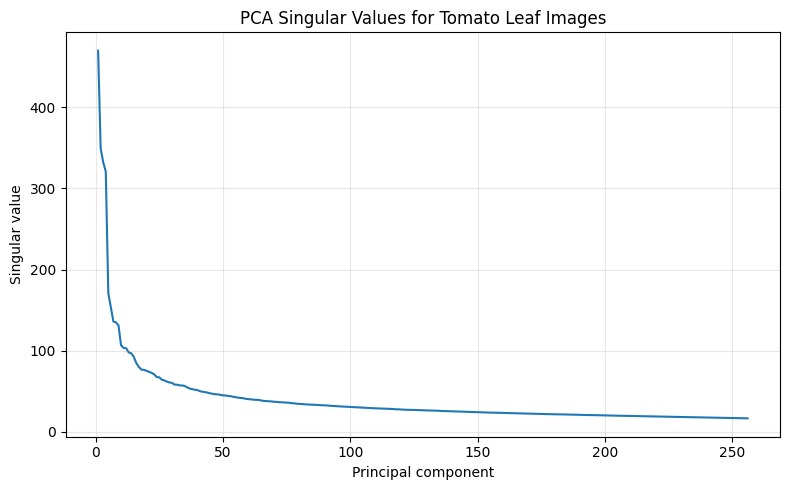

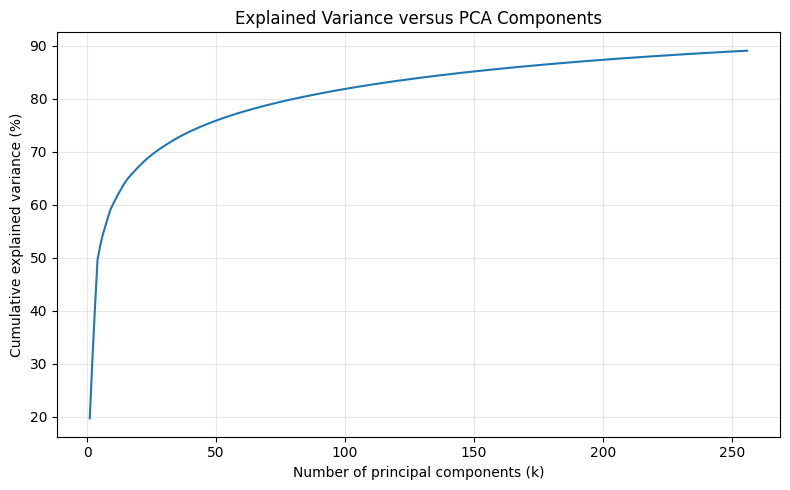

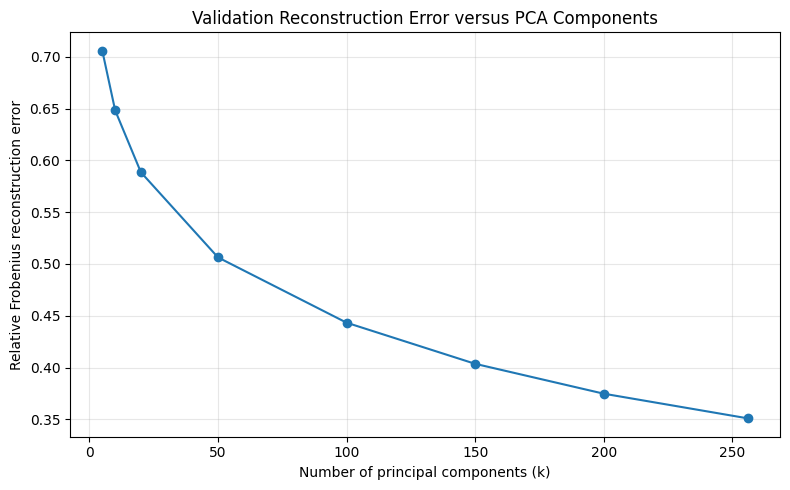

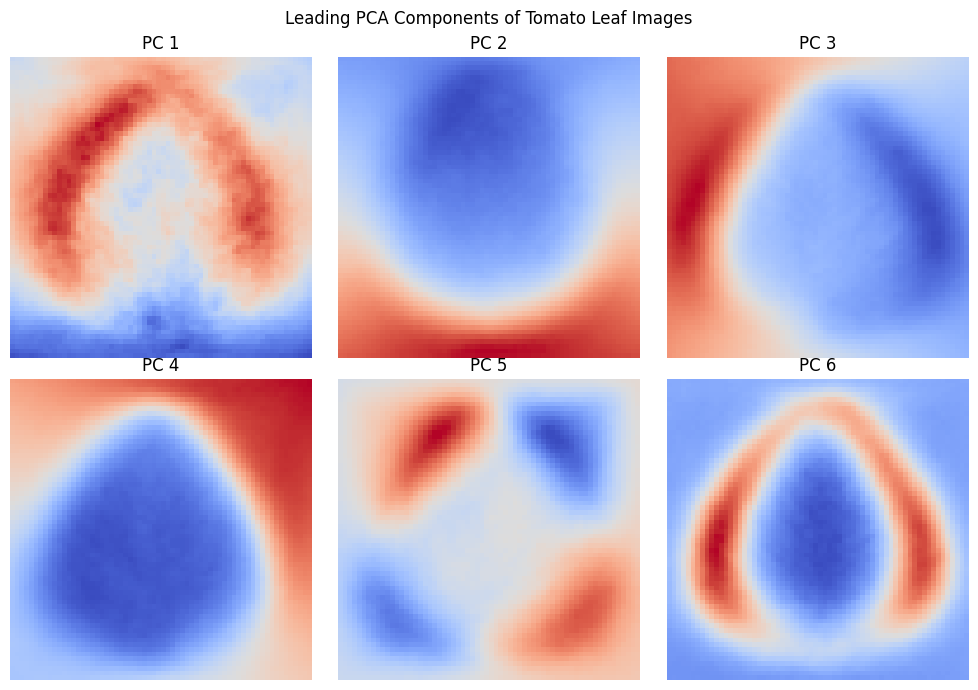


ACTUAL 2x2 COVARIANCE SUBPROBLEM
Pixel indices: 2058 1994
Covariance matrix:
[[0.02932759 0.02667736]
 [0.02667736 0.02894818]]

Manual eigenvalue formula:
lambda = ((a+d) +/- sqrt((a-d)^2 + 4*b^2))/2
a = 0.0293, b = 0.0267, d = 0.0289
Discriminant = 0.0534
lambda_1 = 0.0558
lambda_2 = 0.0025

NumPy eigenvalue verification:
[0.0558 0.0025]

2x2 eigenvalue verification passed.

Outputs saved in: /kaggle/working/agriVision


In [10]:

from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import joblib

# --------------------------------------------------
# 1. Load the already-preprocessed image data
# --------------------------------------------------
OUTPUT_DIR = Path("/kaggle/working/agriVision")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

X_train = np.load(
    OUTPUT_DIR / "X_train_uint8.npy"
).astype(np.float32) / 255.0

X_val = np.load(
    OUTPUT_DIR / "X_val_uint8.npy"
).astype(np.float32) / 255.0

print("Training matrix shape:", X_train.shape)
print("Validation matrix shape:", X_val.shape)

# --------------------------------------------------
# 2. Fit PCA on training data only
# --------------------------------------------------
N_COMPONENTS = 256

pca = PCA(
    n_components=N_COMPONENTS,
    svd_solver="randomized",
    random_state=42,
    iterated_power=4
)

start = perf_counter()
pca.fit(X_train)
pca_fit_seconds = perf_counter() - start

print("\nPCA FIT")
print("Number of components:", N_COMPONENTS)
print(f"Fit time in seconds: {pca_fit_seconds:.4f}")

joblib.dump(pca, OUTPUT_DIR / "tomato_pca_256.joblib")

# --------------------------------------------------
# 3. Relate singular values and covariance eigenvalues
# --------------------------------------------------
singular_values = pca.singular_values_

# For centred training data:
# covariance eigenvalue = singular value squared / (n - 1)
eigenvalues = singular_values**2 / (len(X_train) - 1)

variance_ratio = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(variance_ratio)

print("\nFIRST 10 SINGULAR VALUES AND EIGENVALUES")

spectrum_df = pd.DataFrame({
    "Component": np.arange(1, 11),
    "Singular value": singular_values[:10],
    "Covariance eigenvalue": eigenvalues[:10],
    "Variance ratio": variance_ratio[:10],
    "Cumulative variance": cumulative_variance[:10]
})

print(spectrum_df.round(4).to_string(index=False))

# --------------------------------------------------
# 4. Report explained variance for selected k values
# --------------------------------------------------
candidate_k = [
    k for k in [5, 10, 20, 50, 100, 150, 200, 256]
    if k <= N_COMPONENTS
]

variance_rows = []

for k in candidate_k:
    retained = cumulative_variance[k - 1]
    variance_rows.append({
        "Components k": k,
        "Explained variance (%)": 100 * retained
    })

variance_df = pd.DataFrame(variance_rows)

print("\nEXPLAINED VARIANCE")
print(variance_df.round(4).to_string(index=False))

# --------------------------------------------------
# 5. Validation reconstruction error
# --------------------------------------------------
rng = np.random.default_rng(42)
n_eval = min(200, len(X_val))

selected = rng.choice(
    len(X_val), size=n_eval, replace=False
)

X_eval = X_val[selected]

# Transform centred validation images into PCA space.
Z_eval = pca.transform(X_eval)

# Relative Frobenius error:
# ||X-centred - reconstruction-centred||_F
# --------------------------------------------------
#            ||X-centred||_F
# --------------------------------------------------
X_eval_centered = X_eval - pca.mean_
denominator = np.linalg.norm(X_eval_centered, ord="fro")

reconstruction_rows = []

for k in candidate_k:
    reconstructed_centered = (
        Z_eval[:, :k] @ pca.components_[:k, :]
    )

    numerator = np.linalg.norm(
        X_eval_centered - reconstructed_centered,
        ord="fro"
    )

    relative_error = numerator / denominator

    reconstruction_rows.append({
        "Components k": k,
        "Relative reconstruction error": relative_error,
        "Explained variance (%)": (
            100 * cumulative_variance[k - 1]
        )
    })

reconstruction_df = pd.DataFrame(reconstruction_rows)

print("\nVALIDATION RECONSTRUCTION ERROR")
print(reconstruction_df.round(4).to_string(index=False))

reconstruction_df.to_csv(
    OUTPUT_DIR / "pca_reconstruction_results.csv",
    index=False
)

# --------------------------------------------------
# 6. Plot singular values
# --------------------------------------------------
plt.figure(figsize=(8, 5))
plt.plot(
    np.arange(1, N_COMPONENTS + 1),
    singular_values
)
plt.title("PCA Singular Values for Tomato Leaf Images")
plt.xlabel("Principal component")
plt.ylabel("Singular value")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "pca_singular_values.png", dpi=150)
plt.show()

# --------------------------------------------------
# 7. Plot cumulative explained variance
# --------------------------------------------------
plt.figure(figsize=(8, 5))
plt.plot(
    np.arange(1, N_COMPONENTS + 1),
    100 * cumulative_variance
)
plt.xlabel("Number of principal components (k)")
plt.ylabel("Cumulative explained variance (%)")
plt.title("Explained Variance versus PCA Components")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "pca_explained_variance.png", dpi=150)
plt.show()

# --------------------------------------------------
# 8. Plot reconstruction error
# --------------------------------------------------
plt.figure(figsize=(8, 5))
plt.plot(
    reconstruction_df["Components k"],
    reconstruction_df["Relative reconstruction error"],
    marker="o"
)
plt.xlabel("Number of principal components (k)")
plt.ylabel("Relative Frobenius reconstruction error")
plt.title("Validation Reconstruction Error versus PCA Components")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "pca_reconstruction_error.png", dpi=150)
plt.show()

# --------------------------------------------------
# 9. Visualise the leading principal components
# --------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(10, 7))

for index, ax in enumerate(axes.flat):
    component_image = pca.components_[index].reshape(64, 64)

    ax.imshow(component_image, cmap="coolwarm")
    ax.set_title(f"PC {index + 1}")
    ax.axis("off")

fig.suptitle("Leading PCA Components of Tomato Leaf Images")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "pca_component_images.png", dpi=150)
plt.show()

# --------------------------------------------------
# 10. Extract an actual 2x2 covariance subproblem
# --------------------------------------------------
# Choose a high-variance pixel, then find another
# pixel with the largest absolute covariance to it.
feature_variances = np.var(X_train, axis=0)
pixel_i = int(np.argmax(feature_variances))

centred_i = X_train[:, pixel_i] - X_train[:, pixel_i].mean()

covariances = (
    (X_train - X_train.mean(axis=0)).T @ centred_i
) / (len(X_train) - 1)

covariances[pixel_i] = 0.0
pixel_j = int(np.argmax(np.abs(covariances)))

selected_pixels = X_train[:, [pixel_i, pixel_j]]

cov_matrix = np.cov(
    selected_pixels,
    rowvar=False,
    ddof=1
)

a = float(cov_matrix[0, 0])
b = float(cov_matrix[0, 1])
d = float(cov_matrix[1, 1])

# Analytical eigenvalues for a symmetric 2x2 matrix:
# lambda = ((a+d) +/- sqrt((a-d)^2 + 4b^2))/2
discriminant = np.sqrt((a - d)**2 + 4*b**2)

lambda_1 = ((a + d) + discriminant) / 2
lambda_2 = ((a + d) - discriminant) / 2

print("\nACTUAL 2x2 COVARIANCE SUBPROBLEM")
print("Pixel indices:", pixel_i, pixel_j)
print("Covariance matrix:")
print(cov_matrix)

print("\nManual eigenvalue formula:")
print("lambda = ((a+d) +/- sqrt((a-d)^2 + 4*b^2))/2")
print(f"a = {a:.4f}, b = {b:.4f}, d = {d:.4f}")
print(f"Discriminant = {discriminant:.4f}")
print(f"lambda_1 = {lambda_1:.4f}")
print(f"lambda_2 = {lambda_2:.4f}")

# Numerical verification
numpy_eigenvalues = np.linalg.eigvalsh(cov_matrix)

print("\nNumPy eigenvalue verification:")
print(np.round(numpy_eigenvalues[::-1], 4))

assert np.allclose(
    np.sort([lambda_1, lambda_2]),
    numpy_eigenvalues,
    rtol=1e-4,
    atol=1e-6
)

print("\n2x2 eigenvalue verification passed.")
print("\nOutputs saved in:", OUTPUT_DIR)


In [11]:

from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
from sklearn.decomposition import PCA

OUTPUT_DIR = Path("/kaggle/working/agriVision")

# --------------------------------------------------
# A. Recreate the actual 2x2 covariance subproblem
# --------------------------------------------------
X_train = (
    np.load(OUTPUT_DIR / "X_train_uint8.npy")
    .astype(np.float64) / 255.0
)

feature_variances = np.var(X_train, axis=0)
pixel_i = int(np.argmax(feature_variances))

centred_i = X_train[:, pixel_i] - X_train[:, pixel_i].mean()

covariances = (
    (X_train - X_train.mean(axis=0)).T @ centred_i
) / (len(X_train) - 1)

covariances[pixel_i] = 0.0
pixel_j = int(np.argmax(np.abs(covariances)))

C = np.cov(X_train[:, [pixel_i, pixel_j]],
           rowvar=False, ddof=1)

print("SELECTED PIXELS:", pixel_i, pixel_j)
print("\nCovariance matrix C:")
print(C)

# Characteristic equation:
# lambda^2 - (a+d)*lambda + (a*d-b^2) = 0
a, b, d = C[0, 0], C[0, 1], C[1, 1]

trace = a + d
determinant = a*d - b*b
discriminant = np.sqrt((a-d)**2 + 4*b*b)

lambda_1 = (trace + discriminant) / 2
lambda_2 = (trace - discriminant) / 2

print("\nMANUAL EIGENVALUE CHECK")
print(f"a + d = {trace:.4f}")
print(f"a*d - b^2 = {determinant:.8f}")
print(f"Square-root term = {discriminant:.4f}")
print(f"lambda_1 = {lambda_1:.4f}")
print(f"lambda_2 = {lambda_2:.4f}")

# np.linalg.eigh returns ascending eigenvalues.
eigenvalues, Q = np.linalg.eigh(C)
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
Q = Q[:, order]

Lambda = np.diag(eigenvalues)
C_reconstructed = Q @ Lambda @ Q.T
reconstruction_difference = np.linalg.norm(
    C - C_reconstructed, ord="fro"
)

print("\nEIGENVECTORS (columns of Q):")
print(np.round(Q, 4))

print("\nDIAGONAL EIGENVALUE MATRIX:")
print(np.round(Lambda, 4))

print("\nQ @ Lambda @ Q.T:")
print(np.round(C_reconstructed, 8))

print(
    "\nFrobenius decomposition error:",
    f"{reconstruction_difference:.10f}"
)

assert np.allclose(
    C, C_reconstructed, atol=1e-10
)
assert np.allclose(
    eigenvalues, [lambda_1, lambda_2], atol=1e-10
)

print("Full eigendecomposition verification passed.")

# --------------------------------------------------
# B. Compare PCA fit time across training-set sizes
# Use the same number of components for fairness.
# --------------------------------------------------
sample_sizes = [1000, 5000, 10000, len(X_train)]
rng = np.random.default_rng(42)
timing_rows = []

for n in sample_sizes:
    if n > len(X_train):
        raise ValueError("Requested size exceeds training data.")

    if n == len(X_train):
        X_subset = X_train
    else:
        idx = rng.choice(len(X_train), size=n, replace=False)
        X_subset = X_train[idx]

    model = PCA(
        n_components=64,
        svd_solver="randomized",
        random_state=42,
        iterated_power=3
    )

    start = perf_counter()
    model.fit(X_subset)
    elapsed = perf_counter() - start

    timing_rows.append({
        "Training images": n,
        "Components": 64,
        "Fit time (seconds)": elapsed,
        "Explained variance (%)":
            100 * np.sum(model.explained_variance_ratio_)
    })

timing_df = pd.DataFrame(timing_rows)

print("\nPCA FIT-TIME COMPARISON")
print(timing_df.round(4).to_string(index=False))

timing_df.to_csv(
    OUTPUT_DIR / "pca_fit_time_by_dataset_size.csv",
    index=False
)

print("\nResults saved to:", OUTPUT_DIR)


SELECTED PIXELS: 2058 1994

Covariance matrix C:
[[0.02932759 0.02667736]
 [0.02667736 0.02894818]]

MANUAL EIGENVALUE CHECK
a + d = 0.0583
a*d - b^2 = 0.00013730
Square-root term = 0.0534
lambda_1 = 0.0558
lambda_2 = 0.0025

EIGENVECTORS (columns of Q):
[[-0.7096  0.7046]
 [-0.7046 -0.7096]]

DIAGONAL EIGENVALUE MATRIX:
[[0.0558 0.    ]
 [0.     0.0025]]

Q @ Lambda @ Q.T:
[[0.02932759 0.02667736]
 [0.02667736 0.02894818]]

Frobenius decomposition error: 0.0000000000
Full eigendecomposition verification passed.

PCA FIT-TIME COMPARISON
 Training images  Components  Fit time (seconds)  Explained variance (%)
            1000          64              2.7361                 79.5252
            5000          64              4.4388                 78.0465
           10000          64              4.4004                 78.0261
           12712          64              5.7493                 77.9090

Results saved to: /kaggle/working/agriVision


In [12]:

from pathlib import Path
from time import perf_counter
import json
import gc

import numpy as np
import pandas as pd
import joblib

from sklearn.linear_model import SGDClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score

# --------------------------------------------------
# 1. Load the saved dataset
# --------------------------------------------------
OUTPUT_DIR = Path("/kaggle/working/agriVision")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

X_train = (
    np.load(OUTPUT_DIR / "X_train_uint8.npy")
    .astype(np.float32) / 255.0
)
X_val = (
    np.load(OUTPUT_DIR / "X_val_uint8.npy")
    .astype(np.float32) / 255.0
)

y_train = np.load(OUTPUT_DIR / "y_train.npy")
y_val = np.load(OUTPUT_DIR / "y_val.npy")

with open(
    OUTPUT_DIR / "tomato_class_names.json",
    encoding="utf-8"
) as file:
    class_names = json.load(file)

n_classes = len(class_names)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Number of classes:", n_classes)

# --------------------------------------------------
# 2. Create raw and PCA-compressed representations
# --------------------------------------------------
pca_path = OUTPUT_DIR / "tomato_pca_256.joblib"

if not pca_path.is_file():
    raise FileNotFoundError(
        "PCA model not found. Run the Task 2 PCA cell first."
    )

pca = joblib.load(pca_path)
K = 100

Z_train = pca.transform(X_train)[:, :K].astype(np.float32)
Z_val = pca.transform(X_val)[:, :K].astype(np.float32)

representations = {
    "Raw_4096": (X_train, X_val),
    "PCA_100": (Z_train, Z_val)
}

print("\nFeature representations:")
print("Raw training:", X_train.shape)
print("PCA training:", Z_train.shape)

# --------------------------------------------------
# 3. Define three distinct baseline algorithms
# --------------------------------------------------
model_factories = {
    "SGD_log_loss": lambda: SGDClassifier(
        loss="log_loss",
        alpha=0.0001,
        max_iter=100,
        tol=1e-3,
        random_state=42
    ),

    "KNN_k5": lambda: KNeighborsClassifier(
        n_neighbors=5,
        weights="distance",
        algorithm="brute",
        n_jobs=-1
    ),

    "DecisionTree": lambda: DecisionTreeClassifier(
        max_depth=20,
        min_samples_leaf=2,
        random_state=42
    )
}

# --------------------------------------------------
# 4. Utility functions for probability calculations
# --------------------------------------------------
def predict_probabilities_in_batches(model, X, batch_size=256):
    """Predict class probabilities in chunks to limit memory use."""
    batches = []

    for start in range(0, len(X), batch_size):
        end = min(start + batch_size, len(X))
        batch_prob = model.predict_proba(X[start:end])

        # Align probability columns with class IDs 0,...,n_classes-1.
        aligned = np.zeros(
            (end - start, n_classes),
            dtype=np.float64
        )

        for column, class_id in enumerate(model.classes_):
            aligned[:, int(class_id)] = batch_prob[:, column]

        batches.append(aligned)

    return np.vstack(batches)


def information_metrics(y_true, probabilities):
    """
    Use log base 2, so information quantities are in bits.
    Compare the true marginal class distribution with
    the average predicted probability distribution.
    """
    eps = 1e-12

    # True marginal distribution on the validation set.
    p = (
        np.bincount(y_true, minlength=n_classes)
        / len(y_true)
    ).astype(np.float64)

    # Cross-entropy for each individual prediction.
    row_probabilities = np.clip(probabilities, eps, 1.0)
    row_probabilities /= row_probabilities.sum(
        axis=1, keepdims=True
    )

    individual_ce_bits = -np.mean(
        np.log2(
            row_probabilities[
                np.arange(len(y_true)), y_true
            ]
        )
    )

    # Mean model probabilities form a marginal predicted
    # distribution over the validation set.
    q = probabilities.mean(axis=0)
    q = np.clip(q, eps, None)
    q /= q.sum()

    # H(p) = -sum p_i log2(p_i)
    nonzero_p = p > 0
    H_p = -np.sum(
        p[nonzero_p] * np.log2(p[nonzero_p])
    )

    # H(p,q) = -sum p_i log2(q_i)
    CE_marginal = -np.sum(
        p[nonzero_p] * np.log2(q[nonzero_p])
    )

    # KL(p||q) = sum p_i log2(p_i/q_i)
    KL_pq = np.sum(
        p[nonzero_p] *
        np.log2(p[nonzero_p] / q[nonzero_p])
    )

    # KL(q||p) demonstrates the reverse direction.
    KL_qp = np.sum(
        q[nonzero_p] *
        np.log2(q[nonzero_p] / p[nonzero_p])
    )

    identity_gap = abs(
        CE_marginal - (H_p + KL_pq)
    )

    return {
        "H_true_bits": H_p,
        "Marginal_CE_bits": CE_marginal,
        "KL_true_to_pred_bits": KL_pq,
        "KL_pred_to_true_bits": KL_qp,
        "Identity_check_gap": identity_gap,
        "Per_image_CE_bits": individual_ce_bits
    }, p, q


# --------------------------------------------------
# 5. Train, evaluate and save the six configurations
# --------------------------------------------------
metrics_rows = []
distribution_rows = []
probability_cache = {}

for representation_name, (Xtr, Xv) in representations.items():
    for model_name, make_model in model_factories.items():
        run_name = f"{model_name}_{representation_name}"

        print(f"\nTraining {run_name} ...", flush=True)

        model = make_model()

        start = perf_counter()
        model.fit(Xtr, y_train)
        fit_seconds = perf_counter() - start

        start = perf_counter()
        probabilities = predict_probabilities_in_batches(
            model, Xv
        )
        prediction_seconds = perf_counter() - start

        predictions = probabilities.argmax(axis=1)

        info, true_distribution, predicted_distribution = (
            information_metrics(y_val, probabilities)
        )

        accuracy = accuracy_score(y_val, predictions)
        macro_f1 = f1_score(
            y_val, predictions,
            average="macro",
            zero_division=0
        )

        row = {
            "Model": model_name,
            "Representation": representation_name,
            "Training_time_seconds": fit_seconds,
            "Validation_prediction_time_seconds": prediction_seconds,
            "Accuracy": accuracy,
            "Macro_F1": macro_f1,
            **info
        }

        metrics_rows.append(row)

        # Keep predicted probabilities for use in later tasks.
        probability_cache[run_name] = probabilities

        # Save the trained estimator for reproducibility.
        joblib.dump(
            model,
            OUTPUT_DIR / f"{run_name}.joblib"
        )

        np.save(
            OUTPUT_DIR / f"{run_name}_validation_probabilities.npy",
            probabilities
        )

        for class_id, class_name in enumerate(class_names):
            distribution_rows.append({
                "Model": model_name,
                "Representation": representation_name,
                "Class": class_name,
                "True_validation_probability":
                    true_distribution[class_id],
                "Mean_predicted_probability":
                    predicted_distribution[class_id]
            })

        print(
            f"Accuracy={accuracy:.4f}, "
            f"Macro-F1={macro_f1:.4f}, "
            f"Fit time={fit_seconds:.4f}s, "
            f"Prediction time={prediction_seconds:.4f}s",
            flush=True
        )

        del model, probabilities, predictions
        gc.collect()

# --------------------------------------------------
# 6. Save summary tables
# --------------------------------------------------
metrics_df = pd.DataFrame(metrics_rows)
distributions_df = pd.DataFrame(distribution_rows)

metrics_df.to_csv(
    OUTPUT_DIR / "baseline_information_metrics.csv",
    index=False
)

distributions_df.to_csv(
    OUTPUT_DIR / "validation_class_distributions.csv",
    index=False
)

print("\nBASELINE AND INFORMATION-THEORY RESULTS")
print(
    metrics_df.round(4).to_string(index=False)
)

print("\nSaved output tables and models to:")
print(OUTPUT_DIR)


Training images: 12712
Validation images: 2724
Number of classes: 10

Feature representations:
Raw training: (12712, 4096)
PCA training: (12712, 100)

Training SGD_log_loss_Raw_4096 ...
Accuracy=0.3990, Macro-F1=0.3549, Fit time=213.6941s, Prediction time=0.0255s

Training KNN_k5_Raw_4096 ...


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


Accuracy=0.4486, Macro-F1=0.3644, Fit time=0.0376s, Prediction time=12.7039s

Training DecisionTree_Raw_4096 ...
Accuracy=0.4170, Macro-F1=0.3327, Fit time=78.7767s, Prediction time=0.0119s

Training SGD_log_loss_PCA_100 ...
Accuracy=0.4758, Macro-F1=0.3456, Fit time=3.7198s, Prediction time=0.0082s

Training KNN_k5_PCA_100 ...
Accuracy=0.5683, Macro-F1=0.4936, Fit time=0.0030s, Prediction time=0.4062s

Training DecisionTree_PCA_100 ...
Accuracy=0.4244, Macro-F1=0.3523, Fit time=4.2239s, Prediction time=0.0036s

BASELINE AND INFORMATION-THEORY RESULTS
       Model Representation  Training_time_seconds  Validation_prediction_time_seconds  Accuracy  Macro_F1  H_true_bits  Marginal_CE_bits  KL_true_to_pred_bits  KL_pred_to_true_bits  Identity_check_gap  Per_image_CE_bits
SGD_log_loss       Raw_4096               213.6941                              0.0255    0.3990    0.3549       3.0298            3.2309                0.2011                0.1989                 0.0             5.2895


In [13]:

from pathlib import Path
import numpy as np
import joblib

OUTPUT_DIR = Path("/kaggle/working/agriVision")

# --------------------------------------------------
# PART A: Demonstrate naive softmax failure
# --------------------------------------------------

# Softmax formula:
# softmax(z_i) = exp(z_i) / sum_j exp(z_j)

z = np.array([1000.0, 999.0, 995.0])

print("LOGITS:")
print(z)

with np.errstate(over="ignore", invalid="ignore", divide="ignore"):
    exponentials_naive = np.exp(z)
    denominator_naive = np.sum(exponentials_naive)
    probabilities_naive = exponentials_naive / denominator_naive

print("\nNAIVE SOFTMAX")
print("Exponentials:", exponentials_naive)
print("Denominator:", denominator_naive)
print("Probabilities:", probabilities_naive)
print("All probabilities finite:", np.all(np.isfinite(probabilities_naive)))

# --------------------------------------------------
# PART B: Stable softmax
# --------------------------------------------------

# Stable formula:
# m = max(z)
# softmax(z_i) = exp(z_i - m) / sum_j exp(z_j - m)

m = np.max(z)
shifted_logits = z - m
exponentials_stable = np.exp(shifted_logits)
denominator_stable = np.sum(exponentials_stable)
probabilities_stable = exponentials_stable / denominator_stable

print("\nSTABLE SOFTMAX")
print("Maximum logit:", f"{m:.4f}")
print("Shifted logits:", shifted_logits)
print("Exponentials:", np.round(exponentials_stable, 4))
print("Denominator:", f"{denominator_stable:.4f}")
print("Probabilities:", np.round(probabilities_stable, 4))
print("Probability sum:", f"{probabilities_stable.sum():.4f}")
print("All probabilities finite:", np.all(np.isfinite(probabilities_stable)))

# Log-sum-exp formula:
# log(sum(exp(z))) = m + log(sum(exp(z-m)))
log_sum_exp = m + np.log(np.sum(np.exp(z - m)))

print("\nLOG-SUM-EXP")
print("Stable log-sum-exp:", f"{log_sum_exp:.4f}")

assert np.all(np.isfinite(probabilities_stable))
assert np.isclose(probabilities_stable.sum(), 1.0)

# --------------------------------------------------
# PART C: Covariance conditioning in the retained PCA
# subspace
# --------------------------------------------------

pca_path = OUTPUT_DIR / "tomato_pca_256.joblib"

if not pca_path.is_file():
    raise FileNotFoundError(
        f"PCA model not found: {pca_path}"
    )

pca = joblib.load(pca_path)

# In PCA coordinates, the covariance matrix is diagonal
# with the retained principal-component variances.
variances = np.asarray(
    pca.explained_variance_,
    dtype=np.float64
)

positive_variances = variances[variances > 0]

if len(positive_variances) != len(variances):
    raise ValueError(
        "At least one retained PCA variance is zero; "
        "the condition number is not finite."
    )

lambda_max = float(np.max(positive_variances))
lambda_min = float(np.min(positive_variances))

# For a symmetric positive-definite covariance matrix:
# condition number in the 2-norm = lambda_max / lambda_min
condition_number = lambda_max / lambda_min

print("\nPCA COVARIANCE CONDITIONING")
print("Retained PCA components:", len(variances))
print(f"Largest retained variance: {lambda_max:.8f}")
print(f"Smallest retained variance: {lambda_min:.8f}")
print(f"Condition number: {condition_number:.4f}")

# A larger ratio means some directions have much
# greater variance than others, which can slow gradient
# methods unless the features or optimisation are adjusted.


LOGITS:
[1000.  999.  995.]

NAIVE SOFTMAX
Exponentials: [inf inf inf]
Denominator: inf
Probabilities: [nan nan nan]
All probabilities finite: False

STABLE SOFTMAX
Maximum logit: 1000.0000
Shifted logits: [ 0. -1. -5.]
Exponentials: [1.     0.3679 0.0067]
Denominator: 1.3746
Probabilities: [0.7275 0.2676 0.0049]
Probability sum: 1.0000
All probabilities finite: True

LOG-SUM-EXP
Stable log-sum-exp: 1000.3182

PCA COVARIANCE CONDITIONING
Retained PCA components: 256
Largest retained variance: 17.33952904
Smallest retained variance: 0.02197102
Condition number: 789.2001


C1: depth=2, train_error=0.6573, validation_error=0.6553, gap=-0.0020, fit_time=0.8857s
C2: depth=4, train_error=0.5753, validation_error=0.5815, gap=0.0062, fit_time=1.7320s
C3: depth=8, train_error=0.4541, validation_error=0.5209, gap=0.0668, fit_time=4.5189s
C4: depth=16, train_error=0.1340, validation_error=0.5734, gap=0.4394, fit_time=3.2499s
C5: depth=32, train_error=0.0944, validation_error=0.5712, gap=0.4768, fit_time=3.5994s

CAPACITY RESULTS
Capacity  Max_depth  Training_error  Validation_error  Generalisation_gap  Fit_time_seconds
      C1          2          0.6573            0.6553             -0.0020            0.8857
      C2          4          0.5753            0.5815              0.0062            1.7320
      C3          8          0.4541            0.5209              0.0668            4.5189
      C4         16          0.1340            0.5734              0.4394            3.2499
      C5         32          0.0944            0.5712              0.4768           

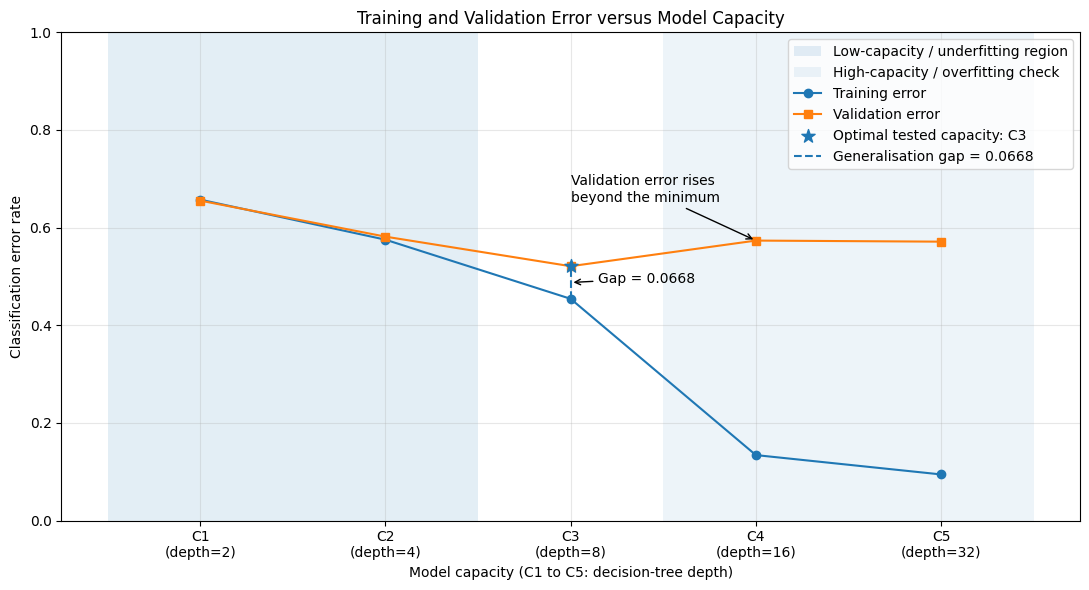


Plot saved to: /kaggle/working/agriVision/capacity_training_validation_error.png
CSV saved to: /kaggle/working/agriVision/capacity_error_results.csv


In [14]:

from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

OUTPUT_DIR = Path("/kaggle/working/agriVision")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load original processed features and labels.
X_train = (
    np.load(OUTPUT_DIR / "X_train_uint8.npy")
    .astype(np.float32) / 255.0
)
X_val = (
    np.load(OUTPUT_DIR / "X_val_uint8.npy")
    .astype(np.float32) / 255.0
)

y_train = np.load(OUTPUT_DIR / "y_train.npy")
y_val = np.load(OUTPUT_DIR / "y_val.npy")

# Apply the PCA transformation fitted on training data only.
pca = joblib.load(OUTPUT_DIR / "tomato_pca_256.joblib")

K = 100
X_train_pca = pca.transform(X_train)[:, :K].astype(np.float32)
X_val_pca = pca.transform(X_val)[:, :K].astype(np.float32)

# C1-C5 represent increasing tree depth.
capacities = {
    "C1": 2,
    "C2": 4,
    "C3": 8,
    "C4": 16,
    "C5": 32
}

results = []

for capacity_name, depth in capacities.items():
    model = DecisionTreeClassifier(
        max_depth=depth,
        min_samples_leaf=2,
        random_state=42
    )

    start = perf_counter()
    model.fit(X_train_pca, y_train)
    fit_time = perf_counter() - start

    train_predictions = model.predict(X_train_pca)
    val_predictions = model.predict(X_val_pca)

    # Error rate = 1 - accuracy
    train_error = 1 - accuracy_score(
        y_train, train_predictions
    )
    val_error = 1 - accuracy_score(
        y_val, val_predictions
    )

    gap = val_error - train_error

    results.append({
        "Capacity": capacity_name,
        "Max_depth": depth,
        "Training_error": train_error,
        "Validation_error": val_error,
        "Generalisation_gap": gap,
        "Fit_time_seconds": fit_time
    })

    print(
        f"{capacity_name}: depth={depth}, "
        f"train_error={train_error:.4f}, "
        f"validation_error={val_error:.4f}, "
        f"gap={gap:.4f}, fit_time={fit_time:.4f}s"
    )

    joblib.dump(
        model,
        OUTPUT_DIR / f"capacity_tree_{capacity_name}.joblib"
    )

results_df = pd.DataFrame(results)

# The optimal capacity is the setting with the lowest
# validation error among these five tested settings.
best_idx = int(
    np.argmin(results_df["Validation_error"].to_numpy())
)
best_row = results_df.iloc[best_idx]

best_capacity = best_row["Capacity"]
best_train_error = best_row["Training_error"]
best_val_error = best_row["Validation_error"]
best_gap = best_row["Generalisation_gap"]

print("\nCAPACITY RESULTS")
print(results_df.round(4).to_string(index=False))

print(
    f"\nOptimal tested capacity: {best_capacity} "
    f"(depth={int(best_row['Max_depth'])})"
)
print(f"Training error: {best_train_error:.4f}")
print(f"Validation error: {best_val_error:.4f}")
print(f"Generalisation gap: {best_gap:.4f}")

# Save numeric results.
results_df.to_csv(
    OUTPUT_DIR / "capacity_error_results.csv",
    index=False
)

# --------------------------------------------------
# Plot training error and validation error.
# --------------------------------------------------
positions = np.arange(len(results_df))

fig, ax = plt.subplots(figsize=(11, 6))

# Low-capacity region: C1-C2.
ax.axvspan(
    -0.5, 1.5,
    alpha=0.12,
    label="Low-capacity / underfitting region"
)

# High-capacity region: C4-C5.
ax.axvspan(
    2.5, 4.5,
    alpha=0.08,
    label="High-capacity / overfitting check"
)

ax.plot(
    positions,
    results_df["Training_error"],
    marker="o",
    label="Training error"
)

ax.plot(
    positions,
    results_df["Validation_error"],
    marker="s",
    label="Validation error"
)

# Mark the lowest observed validation error.
ax.scatter(
    best_idx,
    best_val_error,
    s=100,
    marker="*",
    label=f"Optimal tested capacity: {best_capacity}",
    zorder=5
)

# Mark the generalisation gap at the selected capacity.
ax.vlines(
    best_idx,
    min(best_train_error, best_val_error),
    max(best_train_error, best_val_error),
    linestyles="dashed",
    label=f"Generalisation gap = {best_gap:.4f}"
)

ax.annotate(
    f"Gap = {best_gap:.4f}",
    xy=(best_idx, (best_train_error + best_val_error) / 2),
    xytext=(best_idx + 0.15, (best_train_error + best_val_error) / 2),
    arrowprops={"arrowstyle": "->"}
)

# Determine whether validation error rises beyond its minimum.
val_errors = results_df["Validation_error"].to_numpy()
overfit_indices = [
    i for i in range(best_idx + 1, len(val_errors))
    if val_errors[i] > best_val_error
]

if overfit_indices:
    ax.annotate(
        "Validation error rises\nbeyond the minimum",
        xy=(
            overfit_indices[0],
            val_errors[overfit_indices[0]]
        ),
        xytext=(
            max(0, overfit_indices[0] - 1),
            min(1.0, val_errors[overfit_indices[0]] + 0.08)
        ),
        arrowprops={"arrowstyle": "->"}
    )
else:
    ax.text(
        0.98, 0.04,
        "Overfitting was not demonstrated\nbeyond the selected capacity.",
        transform=ax.transAxes,
        ha="right",
        va="bottom"
    )

ax.set_xticks(positions)
ax.set_xticklabels(
    [
        f"{row.Capacity}\n(depth={row.Max_depth})"
        for row in results_df.itertuples()
    ]
)

ax.set_xlabel("Model capacity (C1 to C5: decision-tree depth)")
ax.set_ylabel("Classification error rate")
ax.set_title(
    "Training and Validation Error versus Model Capacity"
)
ax.set_ylim(0, 1)
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()

plot_path = OUTPUT_DIR / "capacity_training_validation_error.png"
fig.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()

print("\nPlot saved to:", plot_path)
print("CSV saved to:", OUTPUT_DIR / "capacity_error_results.csv")


In [15]:

from pathlib import Path
import json
import numpy as np
import pandas as pd
import joblib

from sklearn.tree import DecisionTreeClassifier

OUTPUT_DIR = Path("/kaggle/working/agriVision")

# --------------------------------------------------
# 1. Load processed features and labels
# --------------------------------------------------
X_train = (
    np.load(OUTPUT_DIR / "X_train_uint8.npy")
    .astype(np.float32) / 255.0
)
X_val = (
    np.load(OUTPUT_DIR / "X_val_uint8.npy")
    .astype(np.float32) / 255.0
)

y_train = np.load(OUTPUT_DIR / "y_train.npy")
y_val = np.load(OUTPUT_DIR / "y_val.npy")

with open(
    OUTPUT_DIR / "tomato_class_names.json",
    encoding="utf-8"
) as f:
    class_names = json.load(f)

n_classes = len(class_names)

# Transform using the PCA model fitted on training data.
pca = joblib.load(OUTPUT_DIR / "tomato_pca_256.joblib")
K = 100

Z_train = pca.transform(X_train)[:, :K].astype(np.float32)
Z_val = pca.transform(X_val)[:, :K].astype(np.float32)

# One-hot encoded validation labels.
Y_val = np.eye(n_classes, dtype=np.float64)[y_val]

# --------------------------------------------------
# 2. Bootstrap bias-variance experiment
# --------------------------------------------------
# At least 10 bootstrap replicas, as required.
B = 10
rng = np.random.default_rng(42)

capacities = {
    "Low capacity (depth 2)": 2,
    "High capacity (depth 32)": 32
}

bias_variance_results = []

for model_name, max_depth in capacities.items():

    bootstrap_predictions = []

    for b in range(B):
        # Draw N training observations with replacement.
        bootstrap_indices = rng.integers(
            0, len(Z_train), size=len(Z_train)
        )

        X_boot = Z_train[bootstrap_indices]
        y_boot = y_train[bootstrap_indices]

        model = DecisionTreeClassifier(
            max_depth=max_depth,
            min_samples_leaf=2,
            random_state=1000 + b
        )

        model.fit(X_boot, y_boot)
        raw_probabilities = model.predict_proba(Z_val)

        # Align class probability columns.
        probabilities = np.zeros(
            (len(Z_val), n_classes),
            dtype=np.float64
        )

        for col, class_id in enumerate(model.classes_):
            probabilities[:, int(class_id)] = (
                raw_probabilities[:, col]
            )

        bootstrap_predictions.append(probabilities)

    # Shape: (B, validation images, classes)
    P = np.stack(bootstrap_predictions, axis=0)

    # Formula: mean bootstrap prediction per validation image.
    mean_prediction = P.mean(axis=0)

    # Empirical squared-bias proxy relative to observed labels.
    bias_squared = np.mean(
        np.sum((mean_prediction - Y_val) ** 2, axis=1)
    )

    # Variance across bootstrap models.
    variance = np.mean(
        np.sum(np.var(P, axis=0, ddof=0), axis=1)
    )

    # Observed mean Brier loss over all bootstrap models.
    brier_per_replica = np.mean(
        np.sum((P - Y_val[None, :, :]) ** 2, axis=2),
        axis=1
    )

    mean_brier = np.mean(brier_per_replica)

    # Finite-sample/numerical residual for this identity.
    residual = mean_brier - bias_squared - variance

    bias_variance_results.append({
        "Model": model_name,
        "Replicas": B,
        "Bias_squared_proxy": bias_squared,
        "Variance": variance,
        "Mean_Brier_loss": mean_brier,
        "Residual": residual
    })

    print(f"\n{model_name}")
    print("Bootstrap replicas:", B)
    print(f"Bias-squared proxy: {bias_squared:.4f}")
    print(f"Variance: {variance:.4f}")
    print(f"Mean Brier loss: {mean_brier:.4f}")
    print(f"Residual: {residual:.8f}")

bias_variance_df = pd.DataFrame(bias_variance_results)

bias_variance_df.to_csv(
    OUTPUT_DIR / "bias_variance_bootstrap.csv",
    index=False
)

print("\nBIAS-VARIANCE SUMMARY")
print(bias_variance_df.round(4).to_string(index=False))

# --------------------------------------------------
# 3. MLE versus MAP with a Beta(2, 2) prior
# --------------------------------------------------
target_class = "Tomato___Tomato_Yellow_Leaf_Curl_Virus"
target_id = class_names.index(target_class)

alpha = 2.0
beta = 2.0

sample_sizes = [100, 500, 1000, 5000, len(y_train)]
sample_sizes = sorted(set(
    n for n in sample_sizes if n <= len(y_train)
))

sample_rng = np.random.default_rng(2026)
estimation_rows = []

for n in sample_sizes:
    if n == len(y_train):
        labels_subset = y_train
    else:
        selected = sample_rng.choice(
            len(y_train), size=n, replace=False
        )
        labels_subset = y_train[selected]

    s = int(np.sum(labels_subset == target_id))

    # MLE: s/n
    mle = s / n

    # MAP for Beta(alpha, beta):
    # (s + alpha - 1) / (n + alpha + beta - 2)
    map_estimate = (
        s + alpha - 1
    ) / (
        n + alpha + beta - 2
    )

    estimation_rows.append({
        "Sample_size_n": n,
        "Target_class_count_s": s,
        "MLE": mle,
        "MAP_Beta_2_2": map_estimate,
        "Absolute_difference": abs(mle - map_estimate)
    })

estimation_df = pd.DataFrame(estimation_rows)

estimation_df.to_csv(
    OUTPUT_DIR / "mle_map_comparison.csv",
    index=False
)

print("\nMLE VS MAP: TARGET CLASS")
print(target_class)
print("Prior: Beta(2, 2)")

print(estimation_df.round(4).to_string(index=False))

print("\nResults saved to:", OUTPUT_DIR)



Low capacity (depth 2)
Bootstrap replicas: 10
Bias-squared proxy: 0.7851
Variance: 0.0027
Mean Brier loss: 0.7878
Residual: 0.00000000

High capacity (depth 32)
Bootstrap replicas: 10
Bias-squared proxy: 0.6166
Variance: 0.5137
Mean Brier loss: 1.1303
Residual: -0.00000000

BIAS-VARIANCE SUMMARY
                   Model  Replicas  Bias_squared_proxy  Variance  Mean_Brier_loss  Residual
  Low capacity (depth 2)        10              0.7851    0.0027           0.7878       0.0
High capacity (depth 32)        10              0.6166    0.5137           1.1303      -0.0

MLE VS MAP: TARGET CLASS
Tomato___Tomato_Yellow_Leaf_Curl_Virus
Prior: Beta(2, 2)
 Sample_size_n  Target_class_count_s    MLE  MAP_Beta_2_2  Absolute_difference
           100                    28 0.2800        0.2843               0.0043
           500                   155 0.3100        0.3108               0.0008
          1000                   279 0.2790        0.2794               0.0004
          5000             

Training shape: (12712, 100)
Validation shape: (2724, 100)
Number of classes: 10

STARTING: BATCH
batch, epoch 1/8: eta=0.001, train=2.3024, val=2.3024, eta=0.010, train=2.3008, val=2.3008, eta=0.100, train=2.2844, val=2.2843
batch, epoch 2/8: eta=0.001, train=2.3022, val=2.3022, eta=0.010, train=2.2989, val=2.2989, eta=0.100, train=2.2666, val=2.2665
batch, epoch 3/8: eta=0.001, train=2.3020, val=2.3020, eta=0.010, train=2.2971, val=2.2971, eta=0.100, train=2.2491, val=2.2490
batch, epoch 4/8: eta=0.001, train=2.3019, val=2.3019, eta=0.010, train=2.2953, val=2.2953, eta=0.100, train=2.2320, val=2.2318
batch, epoch 5/8: eta=0.001, train=2.3017, val=2.3017, eta=0.010, train=2.2935, val=2.2935, eta=0.100, train=2.2153, val=2.2151
batch, epoch 6/8: eta=0.001, train=2.3015, val=2.3015, eta=0.010, train=2.2917, val=2.2916, eta=0.100, train=2.1989, val=2.1987
batch, epoch 7/8: eta=0.001, train=2.3013, val=2.3013, eta=0.010, train=2.2899, val=2.2898, eta=0.100, train=2.1829, val=2.1826
batch,

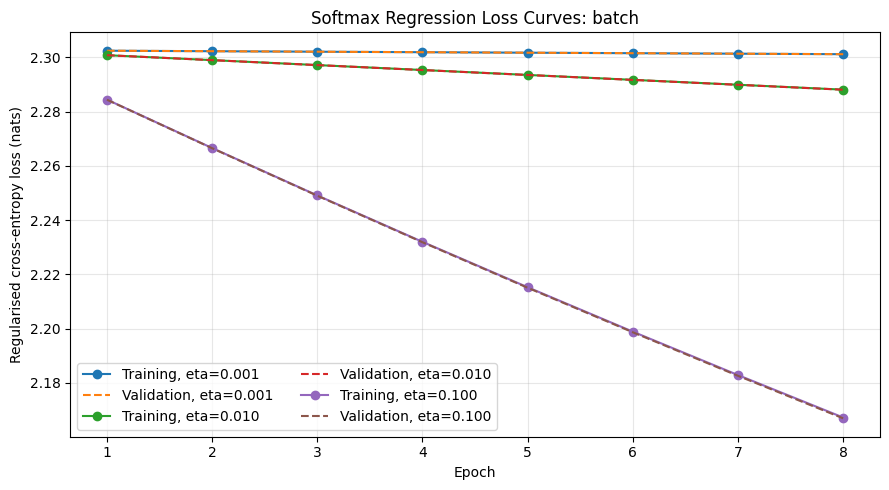

Saved plot: /kaggle/working/agriVision/softmax_loss_batch.png


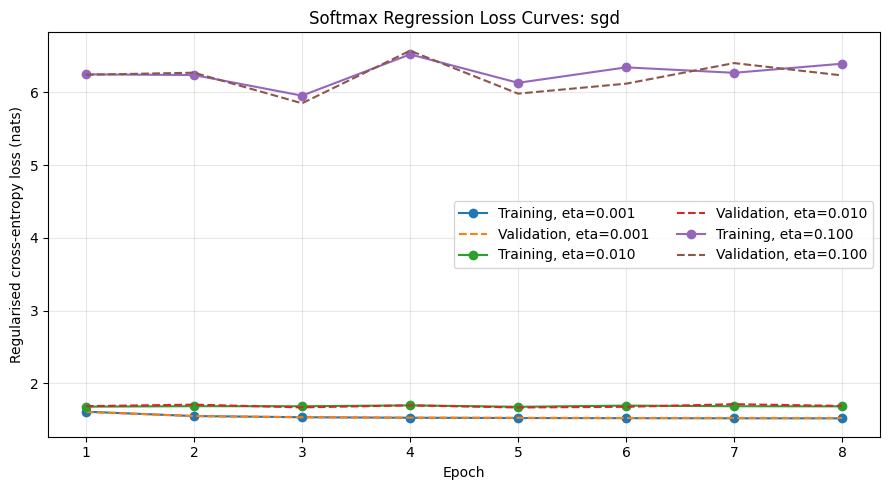

Saved plot: /kaggle/working/agriVision/softmax_loss_sgd.png


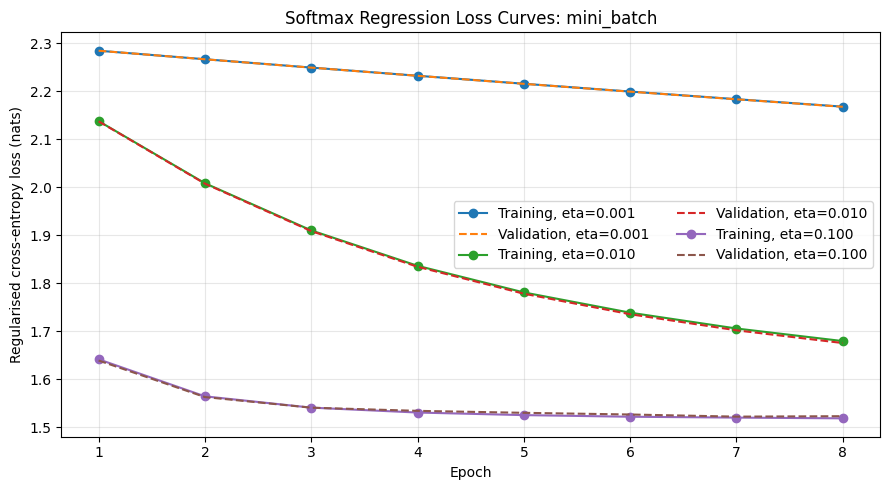

Saved plot: /kaggle/working/agriVision/softmax_loss_mini_batch.png

All Task 8 outputs saved in: /kaggle/working/agriVision


In [16]:

from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

OUTPUT_DIR = Path("/kaggle/working/agriVision")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 1. Load processed data
# --------------------------------------------------
X_train_pixels = np.load(
    OUTPUT_DIR / "X_train_uint8.npy"
).astype(np.float32) / 255.0

X_val_pixels = np.load(
    OUTPUT_DIR / "X_val_uint8.npy"
).astype(np.float32) / 255.0

y_train = np.load(OUTPUT_DIR / "y_train.npy")
y_val = np.load(OUTPUT_DIR / "y_val.npy")

pca = joblib.load(OUTPUT_DIR / "tomato_pca_256.joblib")
K = 100

X_train_pca = pca.transform(X_train_pixels)[:, :K]
X_val_pca = pca.transform(X_val_pixels)[:, :K]

del X_train_pixels, X_val_pixels

# Standardise using training-set statistics only.
# A near-zero standard deviation is replaced by 1.
feature_mean = X_train_pca.mean(axis=0)
feature_std = X_train_pca.std(axis=0)
feature_std[feature_std < 1e-8] = 1.0

X_train = (
    (X_train_pca - feature_mean) / feature_std
).astype(np.float32)

X_val = (
    (X_val_pca - feature_mean) / feature_std
).astype(np.float32)

del X_train_pca, X_val_pca

n_samples, n_features = X_train.shape
n_classes = len(np.unique(y_train))

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Number of classes:", n_classes)

# Three learning rates as required by the assessment.
learning_rates = np.array([0.001, 0.01, 0.1])
lambda_reg = 1e-4
epochs = 8
mini_batch_size = 128

rng = np.random.default_rng(42)

# --------------------------------------------------
# 2. Numerically stable softmax
# --------------------------------------------------
def softmax(logits):
    shifted = logits - np.max(
        logits, axis=-1, keepdims=True
    )
    exp_values = np.exp(shifted)
    return exp_values / np.sum(
        exp_values, axis=-1, keepdims=True
    )


# --------------------------------------------------
# 3. Cross-entropy loss from scratch
# --------------------------------------------------
def calculate_losses(X, y, W, b, batch_size=1024):
    """
    Return training/validation loss for each learning rate.
    W has shape (number_of_rates, features, classes).
    """
    rate_count = W.shape[0]
    total_loss = np.zeros(rate_count, dtype=np.float64)
    total_count = 0

    for start in range(0, len(X), batch_size):
        end = min(start + batch_size, len(X))
        xb = X[start:end]
        yb = y[start:end]

        for r in range(rate_count):
            logits = xb @ W[r] + b[r]
            row_max = np.max(
                logits, axis=1, keepdims=True
            )
            log_sum_exp = (
                row_max[:, 0]
                + np.log(
                    np.exp(logits - row_max).sum(axis=1)
                )
            )

            row_loss = (
                log_sum_exp - logits[np.arange(len(yb)), yb]
            )

            total_loss[r] += row_loss.sum()

        total_count += len(yb)

    mean_loss = total_loss / total_count

    # Add the L2 regularisation penalty.
    mean_loss += (
        0.5 * lambda_reg
        * np.sum(W * W, axis=(1, 2))
    )

    return mean_loss


# --------------------------------------------------
# 4. Train all learning rates for one strategy
# --------------------------------------------------
def train_strategy(strategy):
    rate_count = len(learning_rates)

    # Parameters are trained independently for each rate.
    W = np.zeros(
        (rate_count, n_features, n_classes),
        dtype=np.float64
    )
    b = np.zeros(
        (rate_count, n_classes),
        dtype=np.float64
    )

    history = {
        "epoch": [],
        "train_loss": [],
        "validation_loss": []
    }

    start_time = perf_counter()

    for epoch in range(epochs):
        permutation = rng.permutation(n_samples)

        if strategy == "batch":
            batches = [np.arange(n_samples)]

        elif strategy == "mini_batch":
            batches = [
                permutation[i:i + mini_batch_size]
                for i in range(
                    0, n_samples, mini_batch_size
                )
            ]

        elif strategy == "sgd":
            # Each update uses exactly one training image.
            batches = [
                permutation[i:i + 1]
                for i in range(n_samples)
            ]

        else:
            raise ValueError(
                f"Unknown optimisation strategy: {strategy}"
            )

        for indices in batches:
            xb = X_train[indices]
            yb = y_train[indices]
            batch_n = len(indices)

            # Vectorised computation across learning rates.
            logits = (
                np.einsum("nd,rdc->rnc", xb, W)
                + b[:, None, :]
            )

            probabilities = softmax(logits)
            errors = probabilities.copy()

            rate_indices = np.arange(rate_count)[:, None]
            row_indices = np.arange(batch_n)[None, :]
            errors[
                rate_indices, row_indices, yb[None, :]
            ] -= 1.0

            grad_W = (
                np.einsum("nd,rnc->rdc", xb, errors)
                / batch_n
                + lambda_reg * W
            )

            grad_b = errors.mean(axis=1)

            # Gradient descent updates.
            W -= (
                learning_rates[:, None, None] * grad_W
            )
            b -= learning_rates[:, None] * grad_b

            if (
                not np.isfinite(W).all()
                or not np.isfinite(b).all()
            ):
                raise FloatingPointError(
                    f"Non-finite weights in {strategy}. "
                    "Try smaller learning rates."
                )

        train_loss = calculate_losses(
            X_train, y_train, W, b
        )
        val_loss = calculate_losses(
            X_val, y_val, W, b
        )

        history["epoch"].append(epoch + 1)
        history["train_loss"].append(train_loss.copy())
        history["validation_loss"].append(val_loss.copy())

        print(
            f"{strategy}, epoch {epoch + 1}/{epochs}: "
            + ", ".join(
                f"eta={eta:.3f}, "
                f"train={train_loss[i]:.4f}, "
                f"val={val_loss[i]:.4f}"
                for i, eta in enumerate(learning_rates)
            ),
            flush=True
        )

    elapsed = perf_counter() - start_time

    return W, b, history, elapsed


# --------------------------------------------------
# 5. Run the three optimisation strategies
# --------------------------------------------------
strategies = ["batch", "sgd", "mini_batch"]
experiments = {}
timing_rows = []
final_rows = []

for strategy in strategies:
    print(f"\nSTARTING: {strategy.upper()}")

    W, b, history, elapsed = train_strategy(strategy)

    experiments[strategy] = {
        "W": W,
        "b": b,
        "history": history
    }

    timing_rows.append({
        "Strategy": strategy,
        "Epochs": epochs,
        "Runtime_seconds": elapsed,
        "Runtime_per_epoch_seconds": elapsed / epochs
    })

    # Save the learned parameters and the training history.
    np.save(OUTPUT_DIR / f"softmax_{strategy}_W.npy", W)
    np.save(OUTPUT_DIR / f"softmax_{strategy}_b.npy", b)

    np.savez(
        OUTPUT_DIR / f"softmax_{strategy}_history.npz",
        epochs=np.array(history["epoch"]),
        train_loss=np.array(history["train_loss"]),
        validation_loss=np.array(history["validation_loss"])
    )

    for i, eta in enumerate(learning_rates):
        final_rows.append({
            "Strategy": strategy,
            "Learning_rate": eta,
            "Final_train_loss":
                history["train_loss"][-1][i],
            "Final_validation_loss":
                history["validation_loss"][-1][i],
            "Final_generalisation_gap":
                history["validation_loss"][-1][i]
                - history["train_loss"][-1][i]
        })

timing_df = pd.DataFrame(timing_rows)
final_df = pd.DataFrame(final_rows)

timing_df.to_csv(
    OUTPUT_DIR / "softmax_optimizer_timing.csv",
    index=False
)

final_df.to_csv(
    OUTPUT_DIR / "softmax_final_loss_results.csv",
    index=False
)

print("\nFINAL LOSS SUMMARY")
print(final_df.round(4).to_string(index=False))

print("\nRUNTIME SUMMARY")
print(timing_df.round(4).to_string(index=False))

# --------------------------------------------------
# 6. Create loss plots for each strategy
# --------------------------------------------------
for strategy in strategies:
    history = experiments[strategy]["history"]

    fig, ax = plt.subplots(figsize=(9, 5))

    for i, eta in enumerate(learning_rates):
        ax.plot(
            history["epoch"],
            [values[i] for values in history["train_loss"]],
            marker="o",
            label=f"Training, eta={eta:.3f}"
        )

        ax.plot(
            history["epoch"],
            [
                values[i]
                for values in history["validation_loss"]
            ],
            linestyle="--",
            label=f"Validation, eta={eta:.3f}"
        )

    ax.set_xlabel("Epoch")
    ax.set_ylabel("Regularised cross-entropy loss (nats)")
    ax.set_title(
        f"Softmax Regression Loss Curves: {strategy}"
    )
    ax.grid(True, alpha=0.3)
    ax.legend(ncol=2)
    fig.tight_layout()

    plot_path = (
        OUTPUT_DIR / f"softmax_loss_{strategy}.png"
    )
    fig.savefig(plot_path, dpi=180, bbox_inches="tight")
    plt.show()

    print("Saved plot:", plot_path)

print("\nAll Task 8 outputs saved in:", OUTPUT_DIR)


Training scales: [1000, 5000, 10000, 12712]
Fixed validation images: 2724
Class count: 10

DATASET SIZE=1000, REPRESENTATION=Raw_4096
SGD_log_loss: accuracy=0.3348, macro-F1=0.2030, fit=13.5546s, predict=0.0164s, artifact=0.1575MB
KNN_k5: accuracy=0.4134, macro-F1=0.3295, fit=0.0030s, predict=0.9246s, artifact=15.6335MB
DecisionTree: accuracy=0.3047, macro-F1=0.2293, fit=5.2078s, predict=0.0073s, artifact=0.0545MB

DATASET SIZE=5000, REPRESENTATION=Raw_4096


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


SGD_log_loss: accuracy=0.3322, macro-F1=0.2847, fit=77.5224s, predict=0.0177s, artifact=0.1575MB
KNN_k5: accuracy=0.4255, macro-F1=0.3363, fit=0.0114s, predict=4.3628s, artifact=78.1640MB
DecisionTree: accuracy=0.3616, macro-F1=0.2902, fit=28.7363s, predict=0.0068s, artifact=0.2426MB

DATASET SIZE=10000, REPRESENTATION=Raw_4096


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


SGD_log_loss: accuracy=0.3800, macro-F1=0.3387, fit=164.5771s, predict=0.0936s, artifact=0.1575MB
KNN_k5: accuracy=0.4310, macro-F1=0.3464, fit=0.0613s, predict=21.9737s, artifact=156.3271MB
DecisionTree: accuracy=0.4005, macro-F1=0.3297, fit=63.6722s, predict=0.0082s, artifact=0.4277MB

DATASET SIZE=12712, REPRESENTATION=Raw_4096
SGD_log_loss: accuracy=0.3990, macro-F1=0.3549, fit=213.6941s, predict=0.0169s, artifact=0.1575MB
KNN_k5: accuracy=0.4486, macro-F1=0.3644, fit=0.0376s, predict=12.2001s, artifact=198.7228MB
DecisionTree: accuracy=0.4170, macro-F1=0.3327, fit=78.7767s, predict=0.0064s, artifact=0.5593MB

DATASET SIZE=1000, REPRESENTATION=PCA_100
SGD_log_loss: accuracy=0.3847, macro-F1=0.3006, fit=0.3211s, predict=0.0014s, artifact=0.0050MB
KNN_k5: accuracy=0.4816, macro-F1=0.3980, fit=0.0012s, predict=0.0347s, artifact=0.3899MB
DecisionTree: accuracy=0.3150, macro-F1=0.2503, fit=0.1639s, predict=0.0014s, artifact=0.0668MB

DATASET SIZE=5000, REPRESENTATION=PCA_100
SGD_log_los

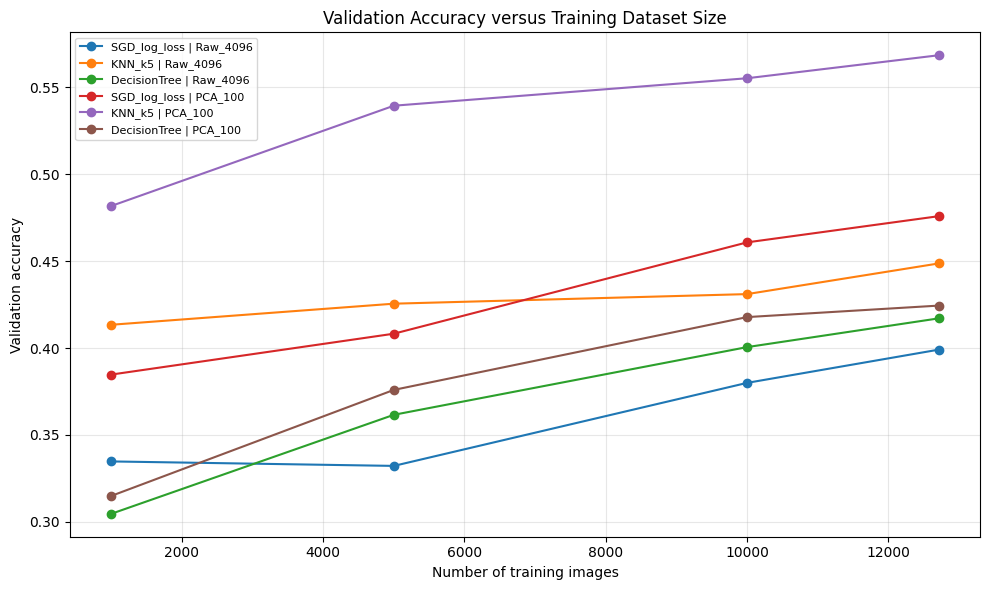

Saved plot: /kaggle/working/agriVision/task9_accuracy_vs_scale.png


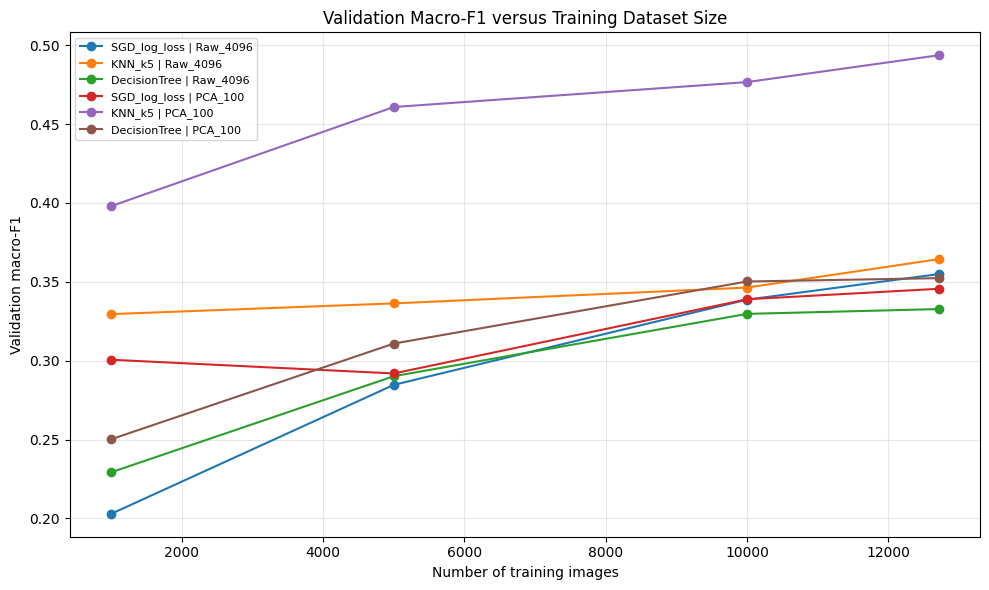

Saved plot: /kaggle/working/agriVision/task9_macro_f1_vs_scale.png


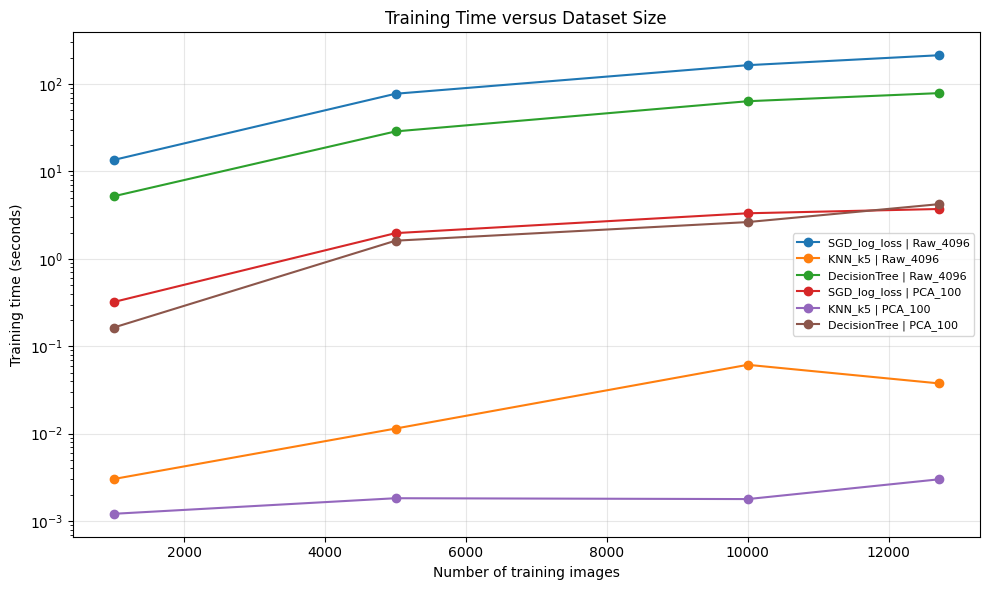


Saved all Task 9 tables, confusion matrices and plots to: /kaggle/working/agriVision


In [17]:

from pathlib import Path
from time import perf_counter
import json
import os
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.linear_model import SGDClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix
)

# --------------------------------------------------
# 1. Load the saved dataset
# --------------------------------------------------
OUT = Path("/kaggle/working/agriVision")
OUT.mkdir(parents=True, exist_ok=True)

X_train_raw = (
    np.load(OUT / "X_train_uint8.npy")
    .astype(np.float32) / 255.0
)
X_val_raw = (
    np.load(OUT / "X_val_uint8.npy")
    .astype(np.float32) / 255.0
)

y_train = np.load(OUT / "y_train.npy")
y_val = np.load(OUT / "y_val.npy")

with open(OUT / "tomato_class_names.json", encoding="utf-8") as f:
    class_names = json.load(f)

n_classes = len(class_names)
class_ids = np.arange(n_classes)
full_size = len(y_train)

# --------------------------------------------------
# 2. Load the PCA model and create 100-component data
# --------------------------------------------------
pca = joblib.load(OUT / "tomato_pca_256.joblib")
K = 100

X_train_pca = (
    pca.transform(X_train_raw)[:, :K].astype(np.float32)
)
X_val_pca = (
    pca.transform(X_val_raw)[:, :K].astype(np.float32)
)

representations = {
    "Raw_4096": (X_train_raw, X_val_raw),
    "PCA_100": (X_train_pca, X_val_pca)
}

# Four required training-data scales.
scales = sorted(set([1000, 5000, 10000, full_size]))

print("Training scales:", scales)
print("Fixed validation images:", len(y_val))
print("Class count:", n_classes)

# --------------------------------------------------
# 3. Define the same baseline hyperparameters
#    used in the earlier comparison
# --------------------------------------------------
def make_model(model_name):
    if model_name == "SGD_log_loss":
        return SGDClassifier(
            loss="log_loss",
            alpha=0.0001,
            max_iter=100,
            tol=1e-3,
            random_state=42
        )

    if model_name == "KNN_k5":
        return KNeighborsClassifier(
            n_neighbors=5,
            weights="distance",
            algorithm="brute",
            n_jobs=-1
        )

    if model_name == "DecisionTree":
        return DecisionTreeClassifier(
            max_depth=20,
            min_samples_leaf=2,
            random_state=42
        )

    raise ValueError(f"Unknown model: {model_name}")


model_names = [
    "SGD_log_loss",
    "KNN_k5",
    "DecisionTree"
]

# Fit times measured in the previous full-training experiment.
# Reuse them only when reusing the corresponding cached model.
previous_full_fit_times = {
    ("SGD_log_loss", "Raw_4096"): 213.6941,
    ("KNN_k5", "Raw_4096"): 0.0376,
    ("DecisionTree", "Raw_4096"): 78.7767,
    ("SGD_log_loss", "PCA_100"): 3.7198,
    ("KNN_k5", "PCA_100"): 0.0030,
    ("DecisionTree", "PCA_100"): 4.2239
}

# --------------------------------------------------
# 4. Storage / complexity measurements
# --------------------------------------------------
def describe_model(model):
    """
    Provide an architecture-specific complexity count.
    Counts are different kinds of proxies across algorithms,
    so they are not directly interchangeable.
    """
    if hasattr(model, "coef_"):
        count = int(model.coef_.size + model.intercept_.size)
        description = "learned coefficients and intercepts"

    elif hasattr(model, "tree_"):
        count = int(model.tree_.node_count)
        description = "decision-tree nodes"

    elif hasattr(model, "_fit_X"):
        # k-NN stores its training feature vectors rather than
        # learning a fixed set of fitted coefficients.
        count = int(model._fit_X.size + len(model._y))
        description = "stored feature values and labels"

    else:
        count = -1
        description = "unavailable"

    return count, description


# --------------------------------------------------
# 5. Train/evaluate all dataset sizes
# --------------------------------------------------
summary_rows = []
per_class_rows = []
best_confusion_data = None

for representation, (Xtr_all, Xv) in representations.items():

    for n in scales:

        # Stratified sampling preserves approximate class proportions.
        if n == full_size:
            selected_idx = np.arange(full_size)
        else:
            selected_idx, _ = train_test_split(
                np.arange(full_size),
                train_size=n,
                stratify=y_train,
                random_state=100 + n
            )

        X_subset = Xtr_all[selected_idx]
        y_subset = y_train[selected_idx]

        print(
            f"\nDATASET SIZE={n}, "
            f"REPRESENTATION={representation}"
        )

        for model_name in model_names:

            # Existing model names come from the original experiments.
            cached_name = f"{model_name}_{representation}"
            cached_path = OUT / f"{cached_name}.joblib"

            if n == full_size and cached_path.exists():
                # Reuse the existing full-size model.
                model = joblib.load(cached_path)
                fit_seconds = previous_full_fit_times[
                    (model_name, representation)
                ]
                fit_source = "previous measured full-size fit"
                model_path = cached_path

            else:
                model = make_model(model_name)

                start = perf_counter()
                model.fit(X_subset, y_subset)
                fit_seconds = perf_counter() - start
                fit_source = "measured in this run"

                model_path = OUT / (
                    f"task9_{model_name}_{representation}_n{n}.joblib"
                )
                joblib.dump(model, model_path)

            # Validation inference timing: one prediction call
            # over the fixed validation set.
            start = perf_counter()
            predictions = model.predict(Xv)
            inference_seconds = perf_counter() - start

            accuracy = accuracy_score(y_val, predictions)

            precision, recall, f1, _ = (
                precision_recall_fscore_support(
                    y_val,
                    predictions,
                    labels=class_ids,
                    average="macro",
                    zero_division=0
                )
            )

            cm = confusion_matrix(
                y_val, predictions, labels=class_ids
            )

            # Save the confusion matrix for this configuration.
            cm_df = pd.DataFrame(
                cm,
                index=class_names,
                columns=class_names
            )
            cm_df.index.name = "Actual"
            cm_df.to_csv(
                OUT / (
                    f"confusion_{model_name}_{representation}_n{n}.csv"
                )
            )

            # Save class-level metrics for detailed interpretation.
            pc_precision, pc_recall, pc_f1, pc_support = (
                precision_recall_fscore_support(
                    y_val,
                    predictions,
                    labels=class_ids,
                    average=None,
                    zero_division=0
                )
            )

            for class_idx, class_name in enumerate(class_names):
                per_class_rows.append({
                    "Training_images": n,
                    "Representation": representation,
                    "Model": model_name,
                    "Class": class_name,
                    "Precision": pc_precision[class_idx],
                    "Recall": pc_recall[class_idx],
                    "F1": pc_f1[class_idx],
                    "Support": pc_support[class_idx]
                })

            complexity_count, complexity_description = (
                describe_model(model)
            )

            artifact_bytes = os.path.getsize(model_path)

            row = {
                "Training_images": n,
                "Representation": representation,
                "Model": model_name,
                "Accuracy": accuracy,
                "Macro_precision": precision,
                "Macro_recall": recall,
                "Macro_F1": f1,
                "Training_time_seconds": fit_seconds,
                "Training_time_source": fit_source,
                "Validation_inference_seconds": inference_seconds,
                "Mean_batch_inference_ms_per_image":
                    1000 * inference_seconds / len(Xv),
                "Complexity_count": complexity_count,
                "Complexity_count_type": complexity_description,
                "Serialized_model_MB": artifact_bytes / (1024 ** 2)
            }

            summary_rows.append(row)

            print(
                f"{model_name}: accuracy={accuracy:.4f}, "
                f"macro-F1={f1:.4f}, "
                f"fit={fit_seconds:.4f}s, "
                f"predict={inference_seconds:.4f}s, "
                f"artifact={artifact_bytes/(1024**2):.4f}MB"
            )

            # Save the macro-F1-best validation confusion matrix.
            # Selection uses validation data only, not test data.
            if (
                best_confusion_data is None
                or f1 > best_confusion_data["Macro_F1"]
            ):
                best_confusion_data = {
                    "Macro_F1": f1,
                    "Model": model_name,
                    "Representation": representation,
                    "Training_images": n,
                    "Confusion_matrix": cm.copy()
                }

            del model, predictions
            gc.collect()

# --------------------------------------------------
# 6. Save summary and class-level results
# --------------------------------------------------
summary_df = pd.DataFrame(summary_rows)
per_class_df = pd.DataFrame(per_class_rows)

summary_df.to_csv(
    OUT / "task9_model_performance_all_scales.csv",
    index=False
)

per_class_df.to_csv(
    OUT / "task9_per_class_metrics.csv",
    index=False
)

print("\nFULL PERFORMANCE SUMMARY")
columns_to_print = [
    "Training_images",
    "Representation",
    "Model",
    "Accuracy",
    "Macro_precision",
    "Macro_recall",
    "Macro_F1",
    "Training_time_seconds",
    "Validation_inference_seconds",
    "Serialized_model_MB"
]
print(
    summary_df[columns_to_print]
    .round(4)
    .to_string(index=False)
)

print("\nBEST VALIDATION MACRO-F1 CONFIGURATION")
print({
    key: value
    for key, value in best_confusion_data.items()
    if key != "Confusion_matrix"
})

best_cm_df = pd.DataFrame(
    best_confusion_data["Confusion_matrix"],
    index=class_names,
    columns=class_names
)
best_cm_df.index.name = "Actual"
best_cm_df.to_csv(OUT / "task9_best_validation_confusion.csv")

# --------------------------------------------------
# 7. Plot accuracy and Macro-F1 against training size
# --------------------------------------------------
for metric, ylabel, filename, title in [
    ("Accuracy", "Validation accuracy",
     "task9_accuracy_vs_scale.png",
     "Validation Accuracy versus Training Dataset Size"),
    ("Macro_F1", "Validation macro-F1",
     "task9_macro_f1_vs_scale.png",
     "Validation Macro-F1 versus Training Dataset Size")
]:
    fig, ax = plt.subplots(figsize=(10, 6))

    for representation in ["Raw_4096", "PCA_100"]:
        for model_name in model_names:
            subset = summary_df[
                (summary_df["Representation"] == representation)
                & (summary_df["Model"] == model_name)
            ].sort_values("Training_images")

            ax.plot(
                subset["Training_images"],
                subset[metric],
                marker="o",
                label=f"{model_name} | {representation}"
            )

    ax.set_xlabel("Number of training images")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
    fig.tight_layout()

    plot_path = OUT / filename
    fig.savefig(plot_path, dpi=180, bbox_inches="tight")
    plt.show()
    print("Saved plot:", plot_path)

# --------------------------------------------------
# 8. Plot training time versus training size
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 6))

for representation in ["Raw_4096", "PCA_100"]:
    for model_name in model_names:
        subset = summary_df[
            (summary_df["Representation"] == representation)
            & (summary_df["Model"] == model_name)
        ].sort_values("Training_images")

        ax.plot(
            subset["Training_images"],
            subset["Training_time_seconds"],
            marker="o",
            label=f"{model_name} | {representation}"
        )

ax.set_xlabel("Number of training images")
ax.set_ylabel("Training time (seconds)")
ax.set_title("Training Time versus Dataset Size")
ax.set_yscale("log")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()

timing_plot_path = OUT / "task9_training_time_vs_scale.png"
fig.savefig(timing_plot_path, dpi=180, bbox_inches="tight")
plt.show()

print("\nSaved all Task 9 tables, confusion matrices and plots to:", OUT)


CONFUSION MATRIX: KNN + PCA-100, 12712 TRAINING IMAGES
                                               Tomato___Bacterial_spot  Tomato___Early_blight  Tomato___Late_blight  Tomato___Leaf_Mold  Tomato___Septoria_leaf_spot  Tomato___Spider_mites Two-spotted_spider_mite  Tomato___Target_Spot  Tomato___Tomato_Yellow_Leaf_Curl_Virus  Tomato___Tomato_mosaic_virus  Tomato___healthy
Actual                                                                                                                                                                                                                                                                                                                           
Tomato___Bacterial_spot                                            246                      1                    14                   2                            8                                              0                     1                                      31                            

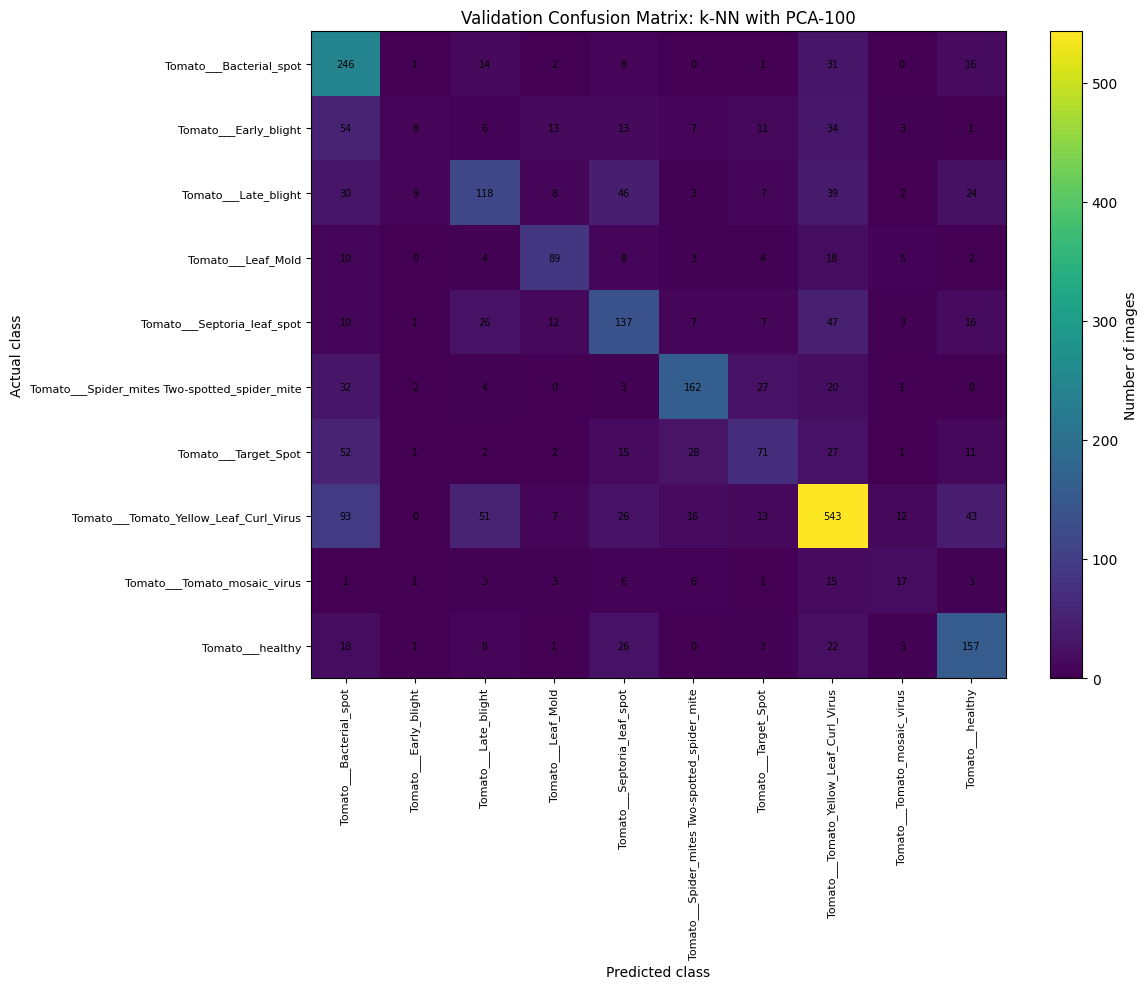


Confusion matrix plot saved to: /kaggle/working/agriVision/task9_confusion_matrix.png


In [18]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

OUT = Path("/kaggle/working/agriVision")

# Inspect the best validation configuration found in Task 9.
cm_path = OUT / "task9_best_validation_confusion.csv"
metrics_path = OUT / "task9_per_class_metrics.csv"

cm_df = pd.read_csv(cm_path, index_col=0)
cm = cm_df.to_numpy(dtype=int)

print("CONFUSION MATRIX: KNN + PCA-100, 12712 TRAINING IMAGES")
print(cm_df.to_string())

# Identify the largest off-diagonal confusion counts.
# Rows are actual classes; columns are predicted classes.
confusions = []

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        if i != j and cm[i, j] > 0:
            confusions.append({
                "Actual_class": cm_df.index[i],
                "Predicted_class": cm_df.columns[j],
                "Misclassified_images": int(cm[i, j])
            })

confusion_df = pd.DataFrame(confusions)

if not confusion_df.empty:
    confusion_df = confusion_df.sort_values(
        "Misclassified_images", ascending=False
    )

    print("\nTOP 10 CLASS CONFUSIONS")
    print(confusion_df.head(10).to_string(index=False))

# Load per-class precision, recall and F1.
metrics_df = pd.read_csv(metrics_path)

best_class_metrics = metrics_df[
    (metrics_df["Training_images"] == 12712)
    & (metrics_df["Representation"] == "PCA_100")
    & (metrics_df["Model"] == "KNN_k5")
].copy()

best_class_metrics = best_class_metrics.sort_values(
    "Recall", ascending=True
)

print("\nPER-CLASS METRICS: LOWEST RECALL FIRST")
print(
    best_class_metrics[
        ["Class", "Precision", "Recall", "F1", "Support"]
    ].round(4).to_string(index=False)
)

# Plot a confusion matrix with matplotlib.
fig, ax = plt.subplots(figsize=(12, 10))

im = ax.imshow(cm, interpolation="nearest", aspect="auto")
fig.colorbar(im, ax=ax, label="Number of images")

ax.set_xticks(np.arange(len(cm_df.columns)))
ax.set_yticks(np.arange(len(cm_df.index)))
ax.set_xticklabels(cm_df.columns, rotation=90, fontsize=8)
ax.set_yticklabels(cm_df.index, fontsize=8)

ax.set_xlabel("Predicted class")
ax.set_ylabel("Actual class")
ax.set_title("Validation Confusion Matrix: k-NN with PCA-100")

# Write cell counts inside the matrix.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center", va="center", fontsize=7
        )

fig.tight_layout()

plot_path = OUT / "task9_confusion_matrix.png"
fig.savefig(plot_path, dpi=180, bbox_inches="tight")
plt.show()

print("\nConfusion matrix plot saved to:", plot_path)



In [19]:

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
import numpy as np
import pandas as pd
import json
import gc

OUT = Path("/kaggle/working/agriVision")
OUT.mkdir(parents=True, exist_ok=True)

# Load the train/validation/test manifests created earlier.
all38_train = pd.read_csv(OUT / "all38_train.csv")
all38_val = pd.read_csv(OUT / "all38_val.csv")
all38_test = pd.read_csv(OUT / "all38_test.csv")

# Use one consistent alphabetical class-ID mapping.
class_names_38 = sorted(set(
    all38_train["label"].unique()
).union(
    all38_val["label"].unique()
).union(
    all38_test["label"].unique()
))

if len(class_names_38) != 38:
    raise ValueError(
        f"Expected 38 classes, found {len(class_names_38)}"
    )

label_to_id_38 = {
    name: idx for idx, name in enumerate(class_names_38)
}

IMAGE_SIZE = (64, 64)
FEATURES = 64 * 64
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

def preprocess_38_split(frame, split_name):
    X = np.empty(
        (len(frame), FEATURES),
        dtype=np.uint8
    )
    y = np.empty(len(frame), dtype=np.int16)

    for i, row in enumerate(
        tqdm(
            frame.itertuples(index=False),
            total=len(frame),
            desc=f"Preprocessing {split_name}"
        )
    ):
        image_path = Path(row.path)

        try:
            with Image.open(image_path) as image:
                gray = image.convert("L")
                resized = gray.resize(
                    IMAGE_SIZE,
                    Image.Resampling.LANCZOS
                )
                X[i] = np.asarray(
                    resized, dtype=np.uint8
                ).reshape(-1)

            y[i] = label_to_id_38[row.label]

        except Exception as exc:
            raise RuntimeError(
                f"Could not process {image_path}"
            ) from exc

    return X, y

# Process each split separately.
X38_train_uint8, y38_train = preprocess_38_split(
    all38_train, "training"
)

X38_val_uint8, y38_val = preprocess_38_split(
    all38_val, "validation"
)

X38_test_uint8, y38_test = preprocess_38_split(
    all38_test, "test"
)

# Save arrays for reuse in later experiments.
arrays = {
    "X38_train_uint8": X38_train_uint8,
    "y38_train": y38_train,
    "X38_val_uint8": X38_val_uint8,
    "y38_val": y38_val,
    "X38_test_uint8": X38_test_uint8,
    "y38_test": y38_test
}

for name, array in arrays.items():
    np.save(OUT / f"{name}.npy", array)

with open(
    OUT / "all38_class_names.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(class_names_38, f, indent=2)

print("38-CLASS PREPROCESSING COMPLETE")
print("Number of classes:", len(class_names_38))
print("Training matrix:", X38_train_uint8.shape)
print("Validation matrix:", X38_val_uint8.shape)
print("Test matrix:", X38_test_uint8.shape)
print("Training labels:", y38_train.shape)
print("Validation labels:", y38_val.shape)
print("Test labels:", y38_test.shape)

print("\nPixel range across training data:")
print(
    int(X38_train_uint8.min()),
    "to",
    int(X38_train_uint8.max())
)

print("\nOutput directory:", OUT)


Preprocessing training:   0%|          | 0/38013 [00:00<?, ?it/s]

Preprocessing validation:   0%|          | 0/8146 [00:00<?, ?it/s]

Preprocessing test:   0%|          | 0/8146 [00:00<?, ?it/s]

38-CLASS PREPROCESSING COMPLETE
Number of classes: 38
Training matrix: (38013, 4096)
Validation matrix: (8146, 4096)
Test matrix: (8146, 4096)
Training labels: (38013,)
Validation labels: (8146,)
Test labels: (8146,)

Pixel range across training data:
0 to 255

Output directory: /kaggle/working/agriVision


In [20]:

from pathlib import Path
from time import perf_counter, perf_counter_ns
import json
import gc
import warnings

import numpy as np
import pandas as pd
import joblib

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)
from sklearn.exceptions import ConvergenceWarning

OUT = Path("/kaggle/working/agriVision")
OUT.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
NOISE_RATE = 0.20
MAX_COMPONENTS = 100

# --------------------------------------------------
# 1. Load the official 38-class splits
# --------------------------------------------------
X_train_u8 = np.load(OUT / "X38_train_uint8.npy")
X_val_u8 = np.load(OUT / "X38_val_uint8.npy")
X_test_u8 = np.load(OUT / "X38_test_uint8.npy")

y_train = np.load(OUT / "y38_train.npy").astype(np.int64)
y_val = np.load(OUT / "y38_val.npy").astype(np.int64)
y_test = np.load(OUT / "y38_test.npy").astype(np.int64)

with open(OUT / "all38_class_names.json", encoding="utf-8") as f:
    class_names = json.load(f)

n_classes = len(class_names)

assert n_classes == 38
assert X_train_u8.shape[1] == 4096

print("TRAINING:", X_train_u8.shape, y_train.shape)
print("VALIDATION:", X_val_u8.shape, y_val.shape)
print("TEST:", X_test_u8.shape, y_test.shape)
print("CLASSES:", n_classes)

# --------------------------------------------------
# 2. Fit PCA using training images only
# --------------------------------------------------
pca = PCA(
    n_components=MAX_COMPONENTS,
    svd_solver="randomized",
    random_state=RANDOM_STATE,
    iterated_power=3
)

print("\nFitting PCA on 38-class training images...")
start = perf_counter()

X_fit = X_train_u8.astype(np.float32) / 255.0
pca.fit(X_fit)

pca_fit_seconds = perf_counter() - start
del X_fit
gc.collect()

joblib.dump(pca, OUT / "all38_pca100.joblib", compress=3)

print(f"PCA fit time: {pca_fit_seconds:.4f} seconds")
print(
    "PCA-100 cumulative explained variance:",
    f"{100 * pca.explained_variance_ratio_.sum():.4f}%"
)

# Transform in batches, avoiding a second large full-size copy.
def transform_u8(Xu8, k, batch_size=512):
    mean = pca.mean_.astype(np.float32)
    components = pca.components_[:k].astype(np.float32)

    result = np.empty(
        (len(Xu8), k), dtype=np.float32
    )

    for start_idx in range(0, len(Xu8), batch_size):
        end_idx = min(start_idx + batch_size, len(Xu8))

        xb = Xu8[start_idx:end_idx].astype(np.float32) / 255.0
        result[start_idx:end_idx] = (
            (xb - mean) @ components.T
        )

    return result

print("\nTransforming all 38-class splits...")
Z_train100 = transform_u8(X_train_u8, 100)
Z_val100 = transform_u8(X_val_u8, 100)
Z_test100 = transform_u8(X_test_u8, 100)

# Standardise using training statistics only.
scaler = StandardScaler()
Z_train100 = scaler.fit_transform(Z_train100).astype(np.float32)
Z_val100 = scaler.transform(Z_val100).astype(np.float32)
Z_test100 = scaler.transform(Z_test100).astype(np.float32)

# Save reusable representations.
np.save(OUT / "all38_train_pca100_scaled.npy", Z_train100)
np.save(OUT / "all38_val_pca100_scaled.npy", Z_val100)
np.save(OUT / "all38_test_pca100_scaled.npy", Z_test100)

print("Standardised training:", Z_train100.shape)
print("Standardised validation:", Z_val100.shape)
print("Standardised test:", Z_test100.shape)

# --------------------------------------------------
# 3. Create exactly 20% noisy training labels
# --------------------------------------------------
y_train_noisy = y_train.copy()
rng = np.random.default_rng(RANDOM_STATE)

n_corrupt = int(round(NOISE_RATE * len(y_train)))
corrupt_indices = rng.choice(
    len(y_train), size=n_corrupt, replace=False
)

# Add a random offset between 1 and 37, ensuring that
# each selected label changes to a different class.
offsets = rng.integers(
    1, n_classes, size=n_corrupt
)

y_train_noisy[corrupt_indices] = (
    y_train_noisy[corrupt_indices] + offsets
) % n_classes

measured_noise_rate = np.mean(y_train_noisy != y_train)

print("\nLABEL-NOISE CHECK")
print("Corrupted training labels:", n_corrupt)
print("Training labels:", len(y_train))
print(f"Measured noise rate: {100 * measured_noise_rate:.4f}%")
print("Validation labels corrupted: 0")
print("Test labels corrupted: 0")

np.save(OUT / "all38_train_labels_noisy20.npy", y_train_noisy)

# --------------------------------------------------
# 4. Define the five comparison configurations
# --------------------------------------------------
configurations = [
    {
        "name": "SGD_log_loss_clean_PCA100",
        "model_type": "log_loss",
        "k": 100,
        "labels": "clean"
    },
    {
        "name": "SGD_log_loss_noisy20_PCA100",
        "model_type": "log_loss",
        "k": 100,
        "labels": "noisy"
    },
    {
        "name": "SGD_modified_huber_noisy20_PCA100",
        "model_type": "modified_huber",
        "k": 100,
        "labels": "noisy"
    },
    {
        "name": "SGD_modified_huber_noisy20_PCA64",
        "model_type": "modified_huber",
        "k": 64,
        "labels": "noisy"
    },
    {
        "name": "KNN_noisy20_PCA100",
        "model_type": "knn",
        "k": 100,
        "labels": "noisy"
    }
]

def make_classifier(model_type):
    if model_type == "log_loss":
        return SGDClassifier(
            loss="log_loss",
            alpha=1e-4,
            max_iter=100,
            tol=1e-3,
            random_state=RANDOM_STATE
        )

    if model_type == "modified_huber":
        return SGDClassifier(
            loss="modified_huber",
            alpha=1e-4,
            max_iter=100,
            tol=1e-3,
            random_state=RANDOM_STATE
        )

    if model_type == "knn":
        return KNeighborsClassifier(
            n_neighbors=5,
            weights="distance",
            algorithm="brute",
            n_jobs=-1
        )

    raise ValueError(model_type)


# --------------------------------------------------
# 5. Measure quality, file size and inference latency
# --------------------------------------------------
def predict_from_one_raw_image(raw_image, artifact):
    """Run preprocessing and classifier prediction for one image."""
    flat = raw_image.astype(np.float32).reshape(1, -1) / 255.0

    pca_features = (
        flat - artifact["pca_mean"]
    ) @ artifact["pca_components"].T

    scaled_features = (
        pca_features - artifact["scaler_mean"]
    ) / artifact["scaler_scale"]

    return artifact["model"].predict(scaled_features)[0]


summary_rows = []
fitted_models = {}

# Fixed random subset for the per-image latency test.
latency_rng = np.random.default_rng(2026)
latency_indices = latency_rng.choice(
    len(X_val_u8), size=min(100, len(X_val_u8)),
    replace=False
)

for config in configurations:
    name = config["name"]
    k = config["k"]
    model_type = config["model_type"]

    print(f"\nTRAINING: {name}", flush=True)

    Xtr = Z_train100[:, :k]
    Xv = Z_val100[:, :k]
    Xt = Z_test100[:, :k]

    train_labels = (
        y_train if config["labels"] == "clean"
        else y_train_noisy
    )

    model = make_classifier(model_type)

    start = perf_counter()
    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(Xtr, train_labels)
    fit_seconds = perf_counter() - start

    warning_text = "; ".join(
        str(w.message)
        for w in captured
        if issubclass(w.category, ConvergenceWarning)
    )

    start = perf_counter()
    val_predictions = model.predict(Xv)
    validation_predict_seconds = perf_counter() - start

    accuracy = accuracy_score(y_val, val_predictions)

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_val,
        val_predictions,
        labels=np.arange(n_classes),
        average="macro",
        zero_division=0
    )

    # Build a compact deployable artifact containing only
    # the required PCA components and standardisation values.
    artifact = {
        "pca_mean": pca.mean_.astype(np.float32),
        "pca_components": pca.components_[:k].astype(np.float32),
        "scaler_mean": scaler.mean_[:k].astype(np.float32),
        "scaler_scale": scaler.scale_[:k].astype(np.float32),
        "model": model,
        "n_components": k,
        "classes": class_names,
        "input_shape": [64, 64],
        "noise_rate_in_training_labels": (
            measured_noise_rate if config["labels"] == "noisy" else 0.0
        )
    }

    artifact_path = OUT / f"{name}.joblib"
    joblib.dump(artifact, artifact_path, compress=3)

    artifact_bytes = artifact_path.stat().st_size
    artifact_mb = artifact_bytes / 1_000_000

    # Warm up before measuring. Include pixel scaling, PCA and
    # classification in each single-image timing.
    for index in latency_indices[:5]:
        predict_from_one_raw_image(
            X_val_u8[index], artifact
        )

    latencies_ms = []

    for index in latency_indices:
        start_ns = perf_counter_ns()
        predict_from_one_raw_image(
            X_val_u8[index], artifact
        )
        elapsed_ms = (
            perf_counter_ns() - start_ns
        ) / 1_000_000
        latencies_ms.append(elapsed_ms)

    p50_ms = float(np.percentile(latencies_ms, 50))
    p95_ms = float(np.percentile(latencies_ms, 95))
    mean_ms = float(np.mean(latencies_ms))

    row = {
        "Configuration": name,
        "Training_labels": config["labels"],
        "Loss_or_model": model_type,
        "PCA_components": k,
        "Validation_accuracy": accuracy,
        "Validation_macro_precision": precision,
        "Validation_macro_recall": recall,
        "Validation_macro_F1": f1,
        "Classifier_fit_seconds": fit_seconds,
        "Validation_batch_prediction_seconds":
            validation_predict_seconds,
        "Pipeline_latency_mean_ms": mean_ms,
        "Pipeline_latency_p50_ms": p50_ms,
        "Pipeline_latency_p95_ms": p95_ms,
        "Saved_pipeline_MB_decimal": artifact_mb,
        "Meets_5MB_artifact_limit": artifact_mb <= 5.0,
        "Meets_50ms_Kaggle_p95_proxy": p95_ms <= 50.0,
        "Convergence_warning": warning_text
    }

    summary_rows.append(row)
    fitted_models[name] = {
        "model": model,
        "artifact": artifact,
        "path": artifact_path,
        "configuration": config
    }

    print(
        f"Validation accuracy={accuracy:.4f}, "
        f"Macro-F1={f1:.4f}, "
        f"Fit={fit_seconds:.4f}s, "
        f"Artifact={artifact_mb:.4f} MB, "
        f"latency p50={p50_ms:.4f} ms, "
        f"p95={p95_ms:.4f} ms",
        flush=True
    )

    if warning_text:
        print("Convergence warning:", warning_text)

    del model, artifact
    gc.collect()

# --------------------------------------------------
# 6. Save and print the experimental comparison
# --------------------------------------------------
summary_df = pd.DataFrame(summary_rows)

summary_df.to_csv(
    OUT / "task12_38class_adaptation_results.csv",
    index=False
)

print("\nTASK 12 VALIDATION RESULTS")
display_columns = [
    "Configuration",
    "PCA_components",
    "Validation_accuracy",
    "Validation_macro_F1",
    "Pipeline_latency_p50_ms",
    "Pipeline_latency_p95_ms",
    "Saved_pipeline_MB_decimal",
    "Meets_5MB_artifact_limit",
    "Meets_50ms_Kaggle_p95_proxy"
]

print(
    summary_df[display_columns]
    .round(4)
    .to_string(index=False)
)

# --------------------------------------------------
# 7. Select the best noisy-label configuration that
#    satisfies both measured proxy constraints.
#    The clean-label model is only a reference.
# --------------------------------------------------
eligible = summary_df[
    (summary_df["Training_labels"] == "noisy")
    & (summary_df["Meets_5MB_artifact_limit"])
    & (summary_df["Meets_50ms_Kaggle_p95_proxy"])
]

if eligible.empty:
    print(
        "\nNo noisy-label configuration met both measured "
        "proxy constraints. A redesign or further compression "
        "is required."
    )
else:
    selected_row = eligible.sort_values(
        "Validation_macro_F1", ascending=False
    ).iloc[0]

    selected_name = selected_row["Configuration"]
    print("\nBEST VALIDATION CONFIGURATION MEETING PROXY LIMITS")
    print(selected_name)
    print(selected_row[display_columns].to_string())

    # --------------------------------------------------
    # 8. Final test evaluation for the selected configuration
    # --------------------------------------------------
    chosen = fitted_models[selected_name]
    k = chosen["configuration"]["k"]
    final_model = chosen["model"]

    start = perf_counter()
    test_predictions = final_model.predict(Z_test100[:, :k])
    test_prediction_seconds = perf_counter() - start

    test_accuracy = accuracy_score(y_test, test_predictions)

    _, _, test_macro_f1, _ = precision_recall_fscore_support(
        y_test,
        test_predictions,
        labels=np.arange(n_classes),
        average="macro",
        zero_division=0
    )

    print("\nFINAL HELD-OUT TEST RESULTS")
    print("Selected model:", selected_name)
    print(f"Test accuracy: {test_accuracy:.4f}")
    print(f"Test macro-F1: {test_macro_f1:.4f}")
    print(
        "Test-set batch prediction time:",
        f"{test_prediction_seconds:.4f} seconds"
    )

    with open(
        OUT / "task12_selected_configuration.json",
        "w",
        encoding="utf-8"
    ) as f:
        json.dump({
            "selected_configuration": selected_name,
            "test_accuracy": float(test_accuracy),
            "test_macro_f1": float(test_macro_f1),
            "test_prediction_seconds": float(test_prediction_seconds),
            "selection_basis": (
                "Highest validation Macro-F1 among noisy-label "
                "configurations meeting the artifact-size and "
                "Kaggle p95 latency proxy limits"
            )
        }, f, indent=2)

    np.save(
        OUT / "task12_selected_test_predictions.npy",
        test_predictions
    )

print("\nResults saved in:", OUT)


TRAINING: (38013, 4096) (38013,)
VALIDATION: (8146, 4096) (8146,)
TEST: (8146, 4096) (8146,)
CLASSES: 38

Fitting PCA on 38-class training images...
PCA fit time: 17.5837 seconds
PCA-100 cumulative explained variance: 85.2584%

Transforming all 38-class splits...
Standardised training: (38013, 100)
Standardised validation: (8146, 100)
Standardised test: (8146, 100)

LABEL-NOISE CHECK
Corrupted training labels: 7603
Training labels: 38013
Measured noise rate: 20.0011%
Validation labels corrupted: 0
Test labels corrupted: 0

TRAINING: SGD_log_loss_clean_PCA100
Validation accuracy=0.3712, Macro-F1=0.2645, Fit=47.3514s, Artifact=1.5524 MB, latency p50=0.4516 ms, p95=0.5641 ms
Convergence warning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.

TRAINING: SGD_log_loss_noisy20_PCA100
Validation accuracy=0.3520, Macro-F1=0.2344, Fit=29.6154s, Artifact=1.5522 MB, latency p50=0.2755 ms, p95=0.3858 ms
Convergence warning: Maximum number of

In [21]:

from pathlib import Path
import json
import numpy as np
import pandas as pd

OUT = Path("/kaggle/working/agriVision")

y_train = np.load(OUT / "y38_train.npy")
y_val = np.load(OUT / "y38_val.npy")

with open(OUT / "all38_class_names.json", encoding="utf-8") as f:
    class_names = json.load(f)

def distribution_summary(labels, class_names):
    counts = np.bincount(
        labels, minlength=len(class_names)
    ).astype(np.float64)

    p = counts / counts.sum()
    positive = p > 0

    # Entropy in bits: H(p) = -sum p_i log2(p_i)
    entropy = -np.sum(
        p[positive] * np.log2(p[positive])
    )

    # Maximum entropy for K classes is log2(K).
    maximum_entropy = np.log2(len(class_names))

    # Majority-class baseline: always predict the most frequent class.
    majority_id = int(np.argmax(counts))
    majority_accuracy = counts[majority_id] / counts.sum()

    result = {
        "Samples": int(counts.sum()),
        "Classes": len(class_names),
        "Entropy_bits": entropy,
        "Maximum_entropy_bits": maximum_entropy,
        "Normalised_entropy": entropy / maximum_entropy,
        "Majority_class": class_names[majority_id],
        "Majority_class_count": int(counts[majority_id]),
        "Majority_baseline_accuracy": majority_accuracy
    }

    distribution = pd.DataFrame({
        "Class": class_names,
        "Count": counts.astype(int),
        "Probability": p
    }).sort_values("Count", ascending=False)

    return result, distribution

train_summary, train_dist = distribution_summary(
    y_train, class_names
)

val_summary, val_dist = distribution_summary(
    y_val, class_names
)

print("38-CLASS TRAIN DISTRIBUTION")
for key, value in train_summary.items():
    print(
        f"{key}: {value:.4f}"
        if isinstance(value, (float, np.floating))
        else f"{key}: {value}"
    )

print("\n38-CLASS VALIDATION DISTRIBUTION")
for key, value in val_summary.items():
    print(
        f"{key}: {value:.4f}"
        if isinstance(value, (float, np.floating))
        else f"{key}: {value}"
    )

# Save the summaries for the final report.
pd.concat([
    train_dist.assign(Split="Training"),
    val_dist.assign(Split="Validation")
]).to_csv(
    OUT / "task12_class_distribution_entropy.csv",
    index=False
)

print(
    "\nSaved class entropy and distribution results to:",
    OUT / "task12_class_distribution_entropy.csv"
)


38-CLASS TRAIN DISTRIBUTION
Samples: 38013
Classes: 38
Entropy_bits: 4.8249
Maximum_entropy_bits: 5.2479
Normalised_entropy: 0.9194
Majority_class: Orange___Haunglongbing_(Citrus_greening)
Majority_class_count: 3855
Majority_baseline_accuracy: 0.1014

38-CLASS VALIDATION DISTRIBUTION
Samples: 8146
Classes: 38
Entropy_bits: 4.8252
Maximum_entropy_bits: 5.2479
Normalised_entropy: 0.9194
Majority_class: Orange___Haunglongbing_(Citrus_greening)
Majority_class_count: 826
Majority_baseline_accuracy: 0.1014

Saved class entropy and distribution results to: /kaggle/working/agriVision/task12_class_distribution_entropy.csv


In [22]:

from pathlib import Path
import pandas as pd
import joblib

OUT = Path("/kaggle/working/agriVision")
results = []

scales = [1000, 5000, 10000, 12712]
representations = ["Raw_4096", "PCA_100"]
models = ["SGD_log_loss", "KNN_k5", "DecisionTree"]

for representation in representations:
    for n in scales:
        for model_name in models:

            if n == 12712:
                model_path = OUT / f"{model_name}_{representation}.joblib"
            else:
                model_path = OUT / (
                    f"task9_{model_name}_{representation}_n{n}.joblib"
                )

            if not model_path.is_file():
                results.append({
                    "Training_images": n,
                    "Representation": representation,
                    "Model": model_name,
                    "Complexity_count": None,
                    "Count_type": "Model file not found"
                })
                continue

            model = joblib.load(model_path)

            if hasattr(model, "coef_"):
                count = model.coef_.size + model.intercept_.size
                count_type = "Learned coefficients and intercepts"

            elif hasattr(model, "tree_"):
                count = model.tree_.node_count
                count_type = "Decision-tree nodes"

            elif hasattr(model, "_fit_X"):
                count = model._fit_X.size + len(model._y)
                count_type = "Stored feature values and labels"

            else:
                count = None
                count_type = "Unavailable"

            results.append({
                "Training_images": n,
                "Representation": representation,
                "Model": model_name,
                "Complexity_count": count,
                "Count_type": count_type,
                "Serialized_model_MB": (
                    model_path.stat().st_size / 1_000_000
                )
            })

complexity_df = pd.DataFrame(results)
complexity_df.to_csv(
    OUT / "task9_model_complexity_counts.csv",
    index=False
)

print(complexity_df.to_string(index=False))
print("\nSaved to:", OUT / "task9_model_complexity_counts.csv")


 Training_images Representation        Model  Complexity_count                          Count_type  Serialized_model_MB
            1000       Raw_4096 SGD_log_loss             40970 Learned coefficients and intercepts             0.165127
            1000       Raw_4096       KNN_k5           4097000    Stored feature values and labels            16.392868
            1000       Raw_4096 DecisionTree               387                 Decision-tree nodes             0.057129
            5000       Raw_4096 SGD_log_loss             40970 Learned coefficients and intercepts             0.165127
            5000       Raw_4096       KNN_k5          20485000    Stored feature values and labels            81.960868
            5000       Raw_4096 DecisionTree              1757                 Decision-tree nodes             0.254409
           10000       Raw_4096 SGD_log_loss             40970 Learned coefficients and intercepts             0.165127
           10000       Raw_4096       KN